# Лабораторная работа 2. Классификация. Нейронные сети

**Датасет:** Pima Indians Diabetes (https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv)

## 1. Введение

**Цель работы** — изучить методы классификации данных, реализованные в Scikit-Learn, а также познакомиться с нейронными сетями на TensorFlow и инструментом визуализации обучения TensorBoard.

**Задачи:**
1. Выбрать и подготовить датасет для бинарной классификации.
2. Построить модели пятью группами методов: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ (LDA), метод опорных векторов (SVM), метод ближайших соседей (kNN).
3. Сравнить их по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.
4. Настроить гиперпараметры каждого метода и исследовать их влияние на качество.
5. Реализовать нейронную сеть на TensorFlow, исследовать влияние гиперпараметров и визуализировать обучение в TensorBoard.
6. Сделать сравнительный анализ и выбрать лучший подход.

In [31]:
import os
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_score, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

SEED = 42                      # единый seed для воспроизводимости
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

Подключены библиотеки и задан единый `SEED = 42`. Он используется в разбиении выборки, в кросс-валидации, в деревьях и в нейронной сети. TensorFlow подключается позже, в разделе про нейросети.

## 2. Выбор и подготовка датасета

Для классификации выбран датасет **Pima Indians Diabetes**: данные обследования женщин индейского племени пима (не младше 21 года). Нужно предсказать, разовьётся ли у пациентки диабет в течение 5 лет. Это бинарная классификация на табличных данных небольшого размера, поэтому на нём удобно сравнивать все требуемые методы.

Загружаю файл. В нём **нет строки заголовка**, поэтому имена столбцов задаю вручную.

In [32]:
COLUMNS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
           "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

DATA_PATH = "pima-indians-diabetes.csv"
URL_FALLBACK = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

src = DATA_PATH if os.path.exists(DATA_PATH) else URL_FALLBACK
df = pd.read_csv(src, header=None, names=COLUMNS)

print("Источник:", src)
print("Размер таблицы:", df.shape)
df.head()

Источник: pima-indians-diabetes.csv
Размер таблицы: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Прочитал таблицу: **768 строк, 8 признаков и целевая переменная `Outcome`**.

| Признак | Описание |
|---|---|
| `Pregnancies` | число беременностей |
| `Glucose` | концентрация глюкозы в плазме через 2 часа после перорального глюкозотолерантного теста |
| `BloodPressure` | диастолическое артериальное давление, мм рт. ст. |
| `SkinThickness` | толщина кожной складки трицепса, мм |
| `Insulin` | сывороточный инсулин через 2 часа, мкЕд/мл |
| `BMI` | индекс массы тела, кг/м² |
| `DiabetesPedigreeFunction` | «функция наследственности» — оценка риска диабета по семейному анамнезу |
| `Age` | возраст, лет |
| **`Outcome`** | **целевая переменная: 1 — диабет, 0 — нет** |

Все признаки числовые.

In [33]:
display(df.describe().T.round(2))
print("Пропусков (NaN):", int(df.isna().sum().sum()))
print("Дубликатов строк:", int(df.duplicated().sum()))

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Пропусков (NaN): 0
Дубликатов строк: 0


Посмотрел описательную статистику и проверил пропуски и дубликаты.

Формально пропусков (`NaN`) и дубликатов нет. Но в столбцах `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` и `BMI` минимум равен **0**, а это физиологически невозможно (нулевое давление, нулевой ИМТ). Значит, пропуски в датасете закодированы нулями. Если оставить их как есть, они исказят средние значения и расстояния между объектами, особенно для kNN, SVM и наивного Байеса.

Outcome
0    500
1    268
Доли классов: {0: 0.651, 1: 0.349}


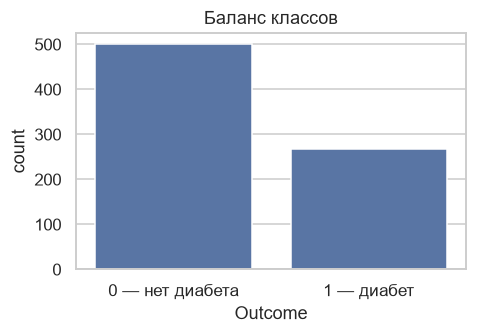

In [34]:
counts = df["Outcome"].value_counts().sort_index()
print(counts.to_string())
print("Доли классов:", (counts / len(df)).round(3).to_dict())

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.countplot(data=df, x="Outcome", ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 — нет диабета", "1 — диабет"])
ax.set_title("Баланс классов")
plt.tight_layout()
plt.show()

Проверил баланс классов.

Класс 0 (нет диабета) — **500** объектов (65,1%), класс 1 (диабет) — **268** (34,9%). Дисбаланс умеренный, но заметный: модель, которая всегда отвечает «нет диабета», получит accuracy ≈ 65%. Поэтому дальше смотрю не только на accuracy, но и на Precision, Recall, F1 и ROC-AUC, а выборку делю со стратификацией.

In [35]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zeros = (df[ZERO_AS_MISSING] == 0).sum().to_frame("число нулей")
zeros["доля, %"] = (zeros["число нулей"] / len(df) * 100).round(1)
display(zeros)

df_clean = df.copy()
df_clean[ZERO_AS_MISSING] = df_clean[ZERO_AS_MISSING].replace(0, np.nan)
print("NaN после замены нулей:", int(df_clean.isna().sum().sum()))

,число нулей,"доля, %"
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


NaN после замены нулей: 652


Посчитал нули в «подозрительных» столбцах и заменил их на `NaN`.

Больше всего скрытых пропусков в `Insulin` (374 нуля, 48,7%) и `SkinThickness` (227, 29,6%). В `BloodPressure` их 35 (4,6%), в `BMI` — 11 (1,4%), в `Glucose` — 5 (0,7%). Всего получилось 652 пропущенных значения. Нули в `Pregnancies` настоящие (0 беременностей), их не трогаю.

Строки с пропусками **не удаляю**: пришлось бы выбросить около половины выборки. Вместо этого значения будут заполнены медианой, причём внутри `Pipeline`, чтобы не было утечки информации из тестовой выборки.

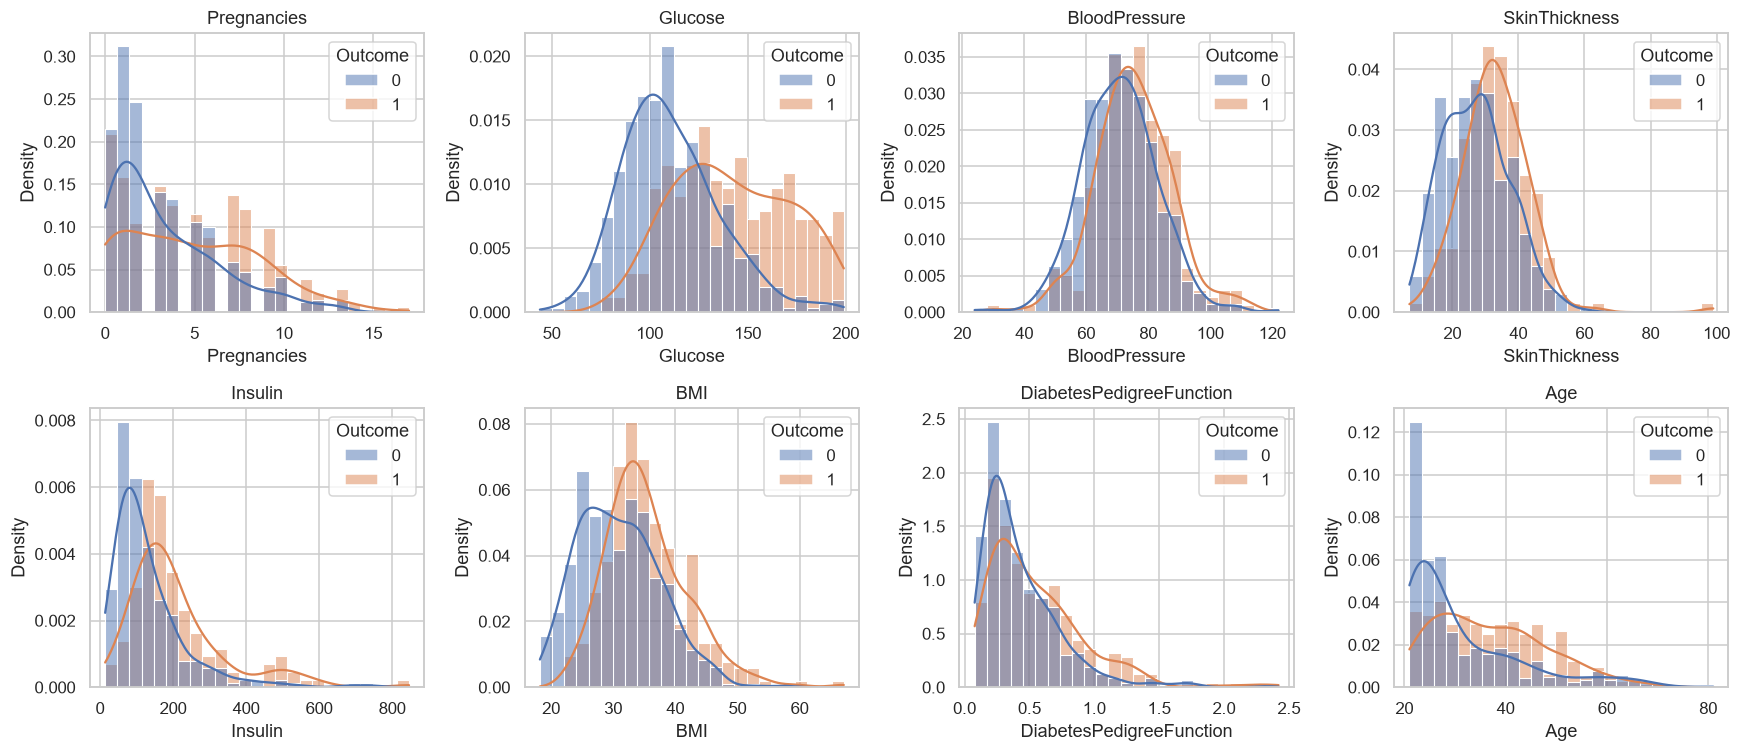

In [36]:
features = COLUMNS[:-1]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df_clean, x=col, hue="Outcome", bins=25, kde=True,
                 stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Построил распределения каждого признака отдельно для здоровых и больных.

Сильнее всего классы различаются по `Glucose`: медиана 107 у здоровых и 140 у больных. Заметный сдвиг есть и у `BMI` (30,1 и 34,3) и `Age` (27 и 36). Распределения `Insulin`, `DiabetesPedigreeFunction` и `Age` скошены вправо (длинный хвост больших значений). Поэтому для заполнения пропусков выбрана медиана, а не среднее: она устойчива к выбросам.

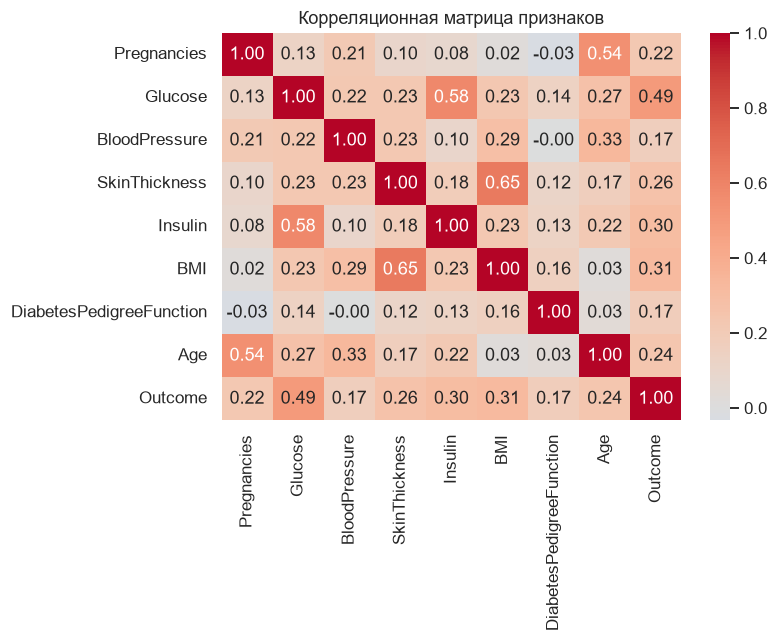

In [37]:
plt.figure(figsize=(7.5, 6))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

Построил матрицу корреляций.

С целевой переменной сильнее всего связаны `Glucose` (0,49), `BMI` (0,31), `Insulin` (0,30), `SkinThickness` (0,26), `Age` (0,24) и `Pregnancies` (0,22); `DiabetesPedigreeFunction` и `BloodPressure` связаны слабее (по 0,17). Между самими признаками есть умеренные корреляции: `SkinThickness`–`BMI` (0,65), `Insulin`–`Glucose` (0,58), `Age`–`Pregnancies` (0,54). Это нарушает «наивное» предположение о независимости признаков в наивном Байесе, и это проявится в результатах. Деревьям решений и SVM такая зависимость не мешает.

## 3. Разбиение выборки и предобработка

Делю данные на обучающую (80%) и тестовую (20%) выборки функцией `train_test_split` со **стратификацией** по `Outcome` и фиксированным `random_state`. Тест используется только один раз, для финальной оценки. Подбор гиперпараметров идёт кросс-валидацией внутри обучающей части.

In [38]:
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("train:", X_train.shape, "| доля класса 1:", round(y_train.mean(), 3))
print("test: ", X_test.shape,  "| доля класса 1:", round(y_test.mean(), 3))

train: (614, 8) | доля класса 1: 0.349
test:  (154, 8) | доля класса 1: 0.351


Получил **614** объектов для обучения и **154** для теста. Доля класса 1 почти одинакова в обеих частях (34,9% и 35,1%), то есть стратификация сработала.

In [39]:
prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # пропуски -> медиана (считается по train)
    ("scaler", StandardScaler()),                    # стандартизация (по train)
])

X_train_prep = pd.DataFrame(prep.fit_transform(X_train), columns=X.columns)
X_test_prep = pd.DataFrame(prep.transform(X_test), columns=X.columns)

print("NaN в train / test после обработки:", int(X_train_prep.isna().sum().sum()), "/", int(X_test_prep.isna().sum().sum()))
display(X_train_prep.describe().loc[["mean", "std"]].round(2))

NaN в train / test после обработки: 0 / 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Показал предобработку на обучающей выборке: пропуски заполняются **медианой**, затем признаки **стандартизируются** (среднее 0, стандартное отклонение 1). Параметры (медианы, средние, std) считаются **только по train** и применяются к тесту, поэтому утечки данных нет. После обработки пропусков не осталось.

Стандартизация нужна методам, чувствительным к масштабу признаков: kNN, SVM, LDA, GaussianNB. Для деревьев она не нужна. А MultinomialNB и ComplementNB требуют неотрицательных признаков, поэтому для них используется масштабирование в диапазон [0, 1] (`MinMaxScaler`).

Дальше импутация и масштабирование включены в `Pipeline` каждой модели, так что при кросс-валидации они пересчитываются на каждом фолде заново.

## 4. Методы классификации

### Наивный байесовский классификатор
Основан на теореме Байеса: $P(y\mid x) \propto P(y)\prod_i P(x_i\mid y)$. «Наивность» состоит в том, что признаки считаются независимыми при заданном классе. Варианты различаются предположением о распределении признака:
- **GaussianNB** — каждый признак имеет нормальное распределение внутри класса. Параметр `var_smoothing` добавляет к дисперсиям небольшую константу для устойчивости.
- **MultinomialNB** — предназначен для счётчиков (например, частоты слов), признаки должны быть неотрицательными. Параметр `alpha` — сглаживание Лапласа.
- **ComplementNB** — вариант Multinomial для несбалансированных данных: статистики считаются по дополнению класса. Параметры: `alpha`, `norm`.
- **BernoulliNB** — для бинарных признаков, вещественные значения превращаются в 0/1 по порогу `binarize`.

Для непрерывных медицинских признаков естественнее всего подходит GaussianNB; остальные три варианта применяются здесь скорее для сравнения.

### Дерево решений
Рекурсивно делит выборку по порогам признаков, выбирая разбиение с наибольшим уменьшением неоднородности (`gini` или `entropy`). Легко интерпретируется и не требует масштабирования, но склонно к переобучению. Ключевые гиперпараметры: `max_depth`, `min_samples_leaf`, `min_samples_split`, `criterion`, `ccp_alpha` (обрезка дерева).

### Линейный дискриминантный анализ (LDA)
Предполагает, что внутри каждого класса данные распределены нормально с **общей** ковариационной матрицей. Граница между классами получается линейной. LDA ищет направление, на которое проекции классов лучше всего разделены. Параметры: `solver` (`svd`, `lsqr`, `eigen`) и `shrinkage` (регуляризация ковариационной матрицы, доступна для `lsqr` и `eigen`).

### Метод опорных векторов (SVM)
Строит разделяющую гиперплоскость с максимальным зазором между классами. С помощью ядер (`linear`, `rbf`, `poly`, `sigmoid`) может строить нелинейные границы. Параметры: `C` (штраф за ошибки: большой `C` — жёсткая граница, риск переобучения), `kernel`, `gamma` (радиус влияния объекта в ядрах rbf/poly/sigmoid), `degree` (степень полинома).

### Метод ближайших соседей (kNN)
Относит объект к классу, который преобладает среди его `k` ближайших соседей в обучающей выборке. Параметры: `n_neighbors`, `weights` (`uniform` или `distance` — вес обратно пропорционален расстоянию), `metric` (евклидова, манхэттенская, Чебышёва). Метод чувствителен к масштабу признаков.

### Метрики качества
Через $TP, FP, TN, FN$ (истинно/ложно положительные и отрицательные ответы):
- **Accuracy** $=\dfrac{TP+TN}{TP+TN+FP+FN}$ — доля верных ответов;
- **Precision** $=\dfrac{TP}{TP+FP}$ — какая доля предсказанных «диабетиков» действительно больна;
- **Recall** $=\dfrac{TP}{TP+FN}$ — какая доля больных найдена;
- **F1** $=\dfrac{2\cdot Precision\cdot Recall}{Precision+Recall}$ — гармоническое среднее Precision и Recall;
- **ROC-AUC** — площадь под кривой «TPR от FPR» при переборе порога классификации; не зависит от выбранного порога, 0,5 — случайное угадывание, 1 — идеальное разделение.

Для скрининга диабета пропуск больного (низкий Recall) обычно хуже, чем ложная тревога, поэтому Recall важен особенно.

In [40]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(clf, scaler="standard"):
    scalers = {
        "standard": StandardScaler(),
        "minmax": MinMaxScaler(clip=True),   # [0, 1]; нужен для Multinomial/Complement NB (признаки >= 0)
        "none": "passthrough",
    }
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", scalers[scaler]),
                     ("clf", clf)])

def get_scores(model, X_):
    """Непрерывная оценка класса 1 (нужна для ROC-AUC)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

def metrics_from(y_true, y_pred, y_score):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall":    recall_score(y_true, y_pred),
            "F1":        f1_score(y_true, y_pred),
            "ROC-AUC":   roc_auc_score(y_true, y_score)}

def evaluate(model, X_, y_):
    return metrics_from(y_, model.predict(X_), get_scores(model, X_))

Подготовил общие инструменты:
- `make_pipe` собирает конвейер «заполнение пропусков → масштабирование → классификатор»;
- кросс-валидация — 5-кратная стратифицированная (`StratifiedKFold`);
- `evaluate` считает Accuracy, Precision, Recall, F1 и ROC-AUC. Для AUC используется `predict_proba` или, если его нет (SVM), `decision_function`.

Для `MinMaxScaler` включён `clip=True`, чтобы значения тестовой выборки, вышедшие за диапазон train, не становились отрицательными (иначе MultinomialNB выдаст ошибку).

### Базовое качество (параметры по умолчанию)

Сначала обучу все методы с настройками по умолчанию, чтобы потом оценить, что дала настройка гиперпараметров. Для каждой модели считаю качество на тесте и среднюю ROC-AUC по 5-кратной кросс-валидации на train (колонка `CV ROC-AUC`).

In [41]:
baseline_models = {
    "GaussianNB":    make_pipe(GaussianNB(), "standard"),
    "MultinomialNB": make_pipe(MultinomialNB(), "minmax"),
    "ComplementNB":  make_pipe(ComplementNB(), "minmax"),
    "BernoulliNB":   make_pipe(BernoulliNB(), "minmax"),
    "DecisionTree":  make_pipe(DecisionTreeClassifier(random_state=SEED), "none"),
    "LDA":           make_pipe(LinearDiscriminantAnalysis(), "standard"),
    "SVM":           make_pipe(SVC(random_state=SEED), "standard"),
    "kNN":           make_pipe(KNeighborsClassifier(), "standard"),
}

rows = []
for name, pipe in baseline_models.items():
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    rows.append({"Модель": name, "CV ROC-AUC (train)": cv_auc, **evaluate(pipe, X_test, y_test)})

baseline_df = pd.DataFrame(rows).set_index("Модель")
display(baseline_df.round(3))

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,,
GaussianNB,0.828,0.701,0.567,0.630,0.596,0.765
MultinomialNB,0.722,0.649,0.000,0.000,0.000,0.767
ComplementNB,0.722,0.734,0.600,0.722,0.655,0.767
BernoulliNB,0.529,0.649,0.000,0.000,0.000,0.554
DecisionTree,0.651,0.682,0.553,0.481,0.515,0.636
LDA,0.843,0.701,0.591,0.481,0.531,0.813
SVM,0.833,0.740,0.652,0.556,0.600,0.796
kNN,0.784,0.753,0.660,0.611,0.635,0.790


Обучил 8 моделей с параметрами по умолчанию.

- По кросс-валидации лучше всего справляются **LDA (0,843), SVM (0,833) и GaussianNB (0,828)**; kNN даёт 0,784.
- **Дерево решений** без ограничений глубины сильно переобучается: CV ROC-AUC всего 0,651.
- **BernoulliNB** почти бесполезен (CV AUC 0,529): порог `binarize=0` превращает почти все признаки (после масштабирования в [0, 1]) в единицы, и информация теряется.
- **MultinomialNB** предсказывает класс 0 для всех объектов (Precision = Recall = 0). Его ранжирование объектов не так плохо (AUC на тесте 0,767), но с порогом 0,5 модель всегда выбирает более частый класс.
- Метрики на тесте (154 объекта) шумные, так что различия в 1–3 пункта нельзя считать значимыми. Поэтому ниже опираюсь и на кросс-валидацию.

## 5. Настройка гиперпараметров

Для каждого метода выполняю два шага:
1. **Кривые валидации**: меняю один гиперпараметр, остальные фиксирую, и смотрю, как меняется ROC-AUC на обучающих данных и на кросс-валидации. По разрыву между кривыми видно переобучение.
2. **Перебор по сетке** (`GridSearchCV`, 5 фолдов, метрика — ROC-AUC): ищу лучшее сочетание параметров на train. Затем лучшая модель оценивается на тесте.

ROC-AUC выбрана как критерий потому, что она не зависит от порога и устойчива к дисбалансу классов. Минус в том, что порог 0,5 при этом не оптимизируется, поэтому Precision, Recall и F1 могут вести себя иначе, чем AUC.

In [42]:
searches, results, roc_data, preds = {}, {}, {}, {}

def clean_params(params):
    out = {}
    for k, v in params.items():
        v = float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, np.integer) else v)
        out[k.split("__")[-1]] = round(v, 6) if isinstance(v, float) else v
    return out

def register(name, y_pred, y_score):
    """Сохраняем метрики на тесте, ROC-кривую и предсказания модели."""
    results[name] = metrics_from(y_test, y_pred, y_score)
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_data[name] = (fpr, tpr)
    preds[name] = y_pred

def tune(name, pipe, grid):
    """Перебор гиперпараметров по сетке: 5-кратная стратифицированная CV на train, метрика — ROC-AUC."""
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    best = gs.best_estimator_
    register(name, best.predict(X_test), get_scores(best, X_test))
    print(f"{name}: CV ROC-AUC = {gs.best_score_:.4f}, лучшие параметры: {clean_params(gs.best_params_)}")
    return gs

def plot_curve(ax, pipe, param, values, title, xlabel, log=False):
    """Кривая валидации: качество на train и на CV в зависимости от одного гиперпараметра."""
    tr, va = validation_curve(pipe, X_train, y_train, param_name=param, param_range=values,
                              cv=cv, scoring="roc_auc", n_jobs=-1)
    ax.plot(values, tr.mean(1), "o--", label="train")
    ax.plot(values, va.mean(1), "o-", label="CV (валидация)")
    ax.fill_between(values, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15)
    if log:
        ax.set_xscale("log")
    ax.set(title=title, xlabel=xlabel, ylabel="ROC-AUC")
    ax.legend()
    i = int(np.argmax(va.mean(1)))
    return values[i], va.mean(1)[i]

Написал вспомогательные функции: `plot_curve` строит кривую валидации, `tune` запускает `GridSearchCV`, оценивает лучшую модель на тесте и сохраняет метрики и ROC-кривую для итогового сравнения.

### 5.1. Наивный байесовский классификатор

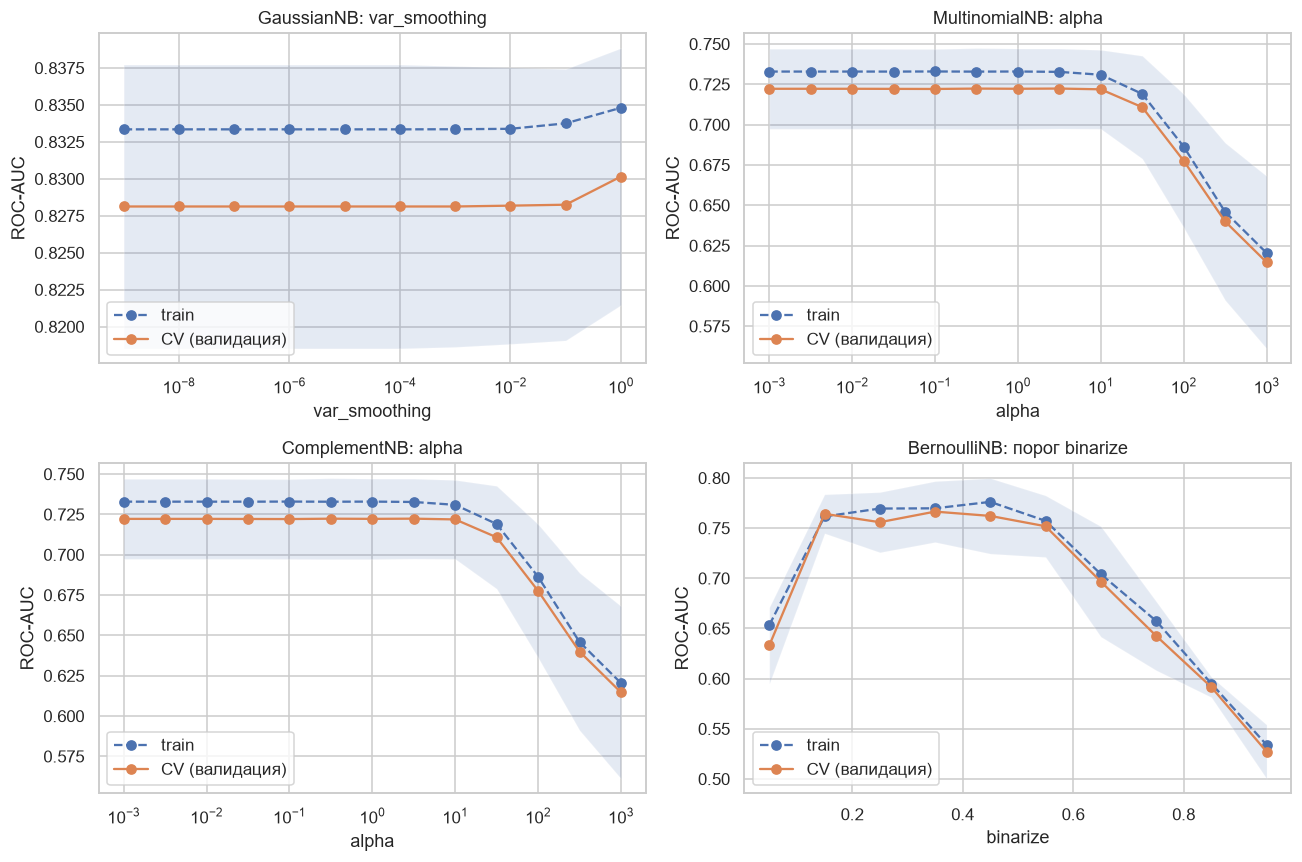

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_curve(axes[0, 0], make_pipe(GaussianNB()), "clf__var_smoothing",
           np.logspace(-9, 0, 10), "GaussianNB: var_smoothing", "var_smoothing", log=True)
plot_curve(axes[0, 1], make_pipe(MultinomialNB(), "minmax"), "clf__alpha",
           np.logspace(-3, 3, 13), "MultinomialNB: alpha", "alpha", log=True)
plot_curve(axes[1, 0], make_pipe(ComplementNB(), "minmax"), "clf__alpha",
           np.logspace(-3, 3, 13), "ComplementNB: alpha", "alpha", log=True)
plot_curve(axes[1, 1], make_pipe(BernoulliNB(), "minmax"), "clf__binarize",
           np.linspace(0.05, 0.95, 10), "BernoulliNB: порог binarize", "binarize")
plt.tight_layout()
plt.show()

Построил кривые валидации для всех четырёх вариантов наивного Байеса.

- **GaussianNB, `var_smoothing`:** до значений порядка $10^{-2}$ параметр ни на что не влияет: признаки стандартизованы, и такая добавка к дисперсии ничтожна. Лишь при значениях около 1 CV-качество слегка растёт.
- **MultinomialNB и ComplementNB, `alpha`:** качество постоянно при `alpha` до 10, а при больших значениях падает, потому что сильное сглаживание стирает различия между классами.
- **BernoulliNB, `binarize`:** самый чувствительный параметр. Рабочий диапазон порога примерно 0,15–0,55 (лучше около 0,4). При 0,05 почти все признаки становятся единицами, при 0,95 — нулями, и модель теряет информацию.

In [44]:
alphas = np.logspace(-3, 3, 13)
nb_specs = {
    "GaussianNB":    (make_pipe(GaussianNB()),
                      {"clf__var_smoothing": np.logspace(-9, 0, 19)}),
    "MultinomialNB": (make_pipe(MultinomialNB(), "minmax"),
                      {"clf__alpha": alphas, "clf__fit_prior": [True, False]}),
    "ComplementNB":  (make_pipe(ComplementNB(), "minmax"),
                      {"clf__alpha": alphas, "clf__norm": [True, False], "clf__fit_prior": [True, False]}),
    "BernoulliNB":   (make_pipe(BernoulliNB(), "minmax"),
                      {"clf__alpha": alphas, "clf__binarize": np.linspace(0.1, 0.9, 9),
                       "clf__fit_prior": [True, False]}),
}
for name, (pipe, grid) in nb_specs.items():
    tune(name, pipe, grid)

nb_table = pd.DataFrame({n: {"CV ROC-AUC": searches[n].best_score_, **results[n]} for n in nb_specs}).T
display(nb_table.round(3))

GaussianNB: CV ROC-AUC = 0.8302, лучшие параметры: {'var_smoothing': 1.0}
MultinomialNB: CV ROC-AUC = 0.7224, лучшие параметры: {'alpha': 3.162278, 'fit_prior': True}
ComplementNB: CV ROC-AUC = 0.7224, лучшие параметры: {'alpha': 3.162278, 'fit_prior': True, 'norm': False}
BernoulliNB: CV ROC-AUC = 0.7735, лучшие параметры: {'alpha': 100.0, 'binarize': 0.4, 'fit_prior': True}


,CV ROC-AUC,Accuracy,Precision,Recall,F1,ROC-AUC
GaussianNB,0.830,0.721,0.641,0.463,0.538,0.773
MultinomialNB,0.722,0.649,0.000,0.000,0.000,0.768
ComplementNB,0.722,0.734,0.600,0.722,0.655,0.768
BernoulliNB,0.773,0.656,0.526,0.185,0.274,0.740


Подобрал параметры для каждого варианта по сетке.

- **GaussianNB** — лучший по CV (0,830, `var_smoothing = 1`). Но выигрыш от настройки мал: 0,828 → 0,830.
- **MultinomialNB и ComplementNB** — CV AUC практически одинаков (0,722). Различаются они порогом: ComplementNB находит больше больных (Recall 0,72, F1 0,66 — лучший F1 среди классических моделей на тесте), а MultinomialNB по-прежнему предсказывает только класс 0.
- **BernoulliNB** — настройка дала самый большой прирост: CV AUC с 0,529 до 0,773. Но его Recall низкий (0,19): модель осторожничает и редко предсказывает диабет.
- Для непрерывных признаков GaussianNB подходит заметно лучше остальных вариантов: Multinomial, Complement и Bernoulli рассчитаны на счётчики и бинарные признаки.

### 5.2. Дерево решений

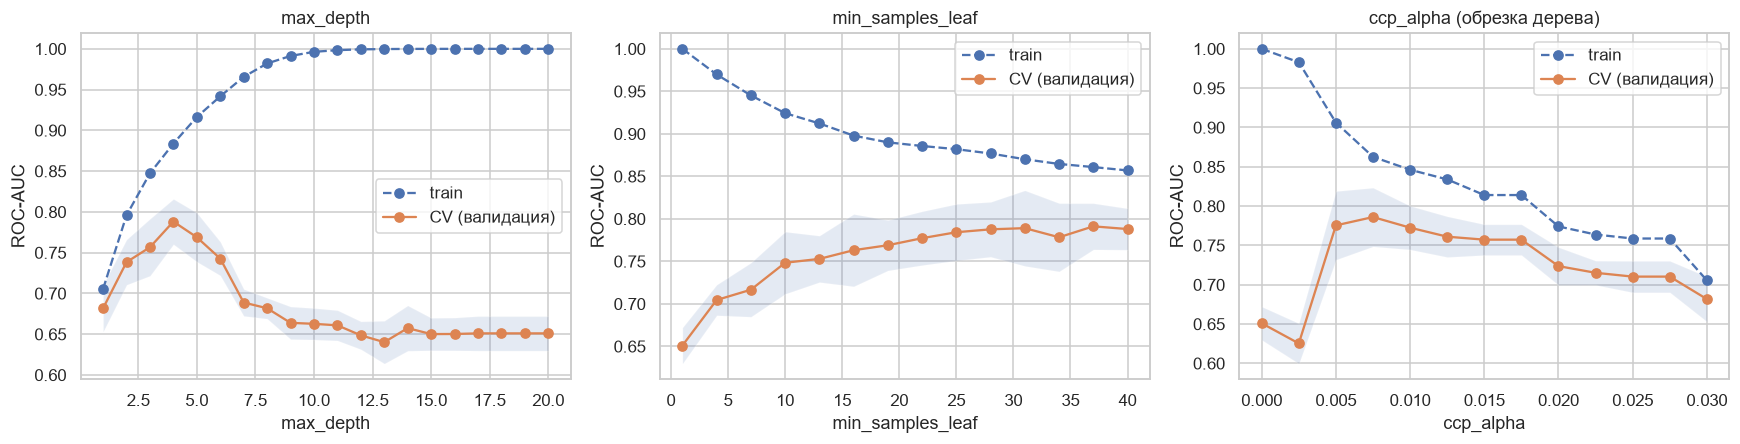

In [45]:
dt_pipe = make_pipe(DecisionTreeClassifier(random_state=SEED), "none")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_curve(axes[0], dt_pipe, "clf__max_depth", np.arange(1, 21), "max_depth", "max_depth")
plot_curve(axes[1], dt_pipe, "clf__min_samples_leaf", np.arange(1, 41, 3), "min_samples_leaf", "min_samples_leaf")
plot_curve(axes[2], dt_pipe, "clf__ccp_alpha", np.linspace(0, 0.03, 13), "ccp_alpha (обрезка дерева)", "ccp_alpha")
plt.tight_layout()
plt.show()

Изучил три параметра, ограничивающих сложность дерева.

- **`max_depth`:** качество на train растёт до 1,0 (дерево запоминает обучающую выборку), а на CV достигает максимума при глубине около 4 (≈0,79) и затем падает до 0,65 — классическое переобучение.
- **`min_samples_leaf`:** чем больше минимальный размер листа, тем меньше разрыв между train и CV и тем выше CV-качество (выходит на плато при значениях около 25–40).
- **`ccp_alpha`:** небольшая обрезка (≈0,005–0,01) резко улучшает CV-качество по сравнению с необрезанным деревом.

Во всех трёх случаях ограничение сложности — главный способ улучшить дерево.

In [46]:
dt_grid = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "clf__min_samples_leaf": [1, 2, 5, 10, 20, 30, 40],
    "clf__min_samples_split": [2, 10, 20],
}
gs_dt = tune("DecisionTree", make_pipe(DecisionTreeClassifier(random_state=SEED), "none"), dt_grid)

cv_dt = pd.DataFrame(gs_dt.cv_results_)
display(cv_dt.groupby("param_clf__criterion")["mean_test_score"].agg(["mean", "max"]).round(4))

DecisionTree: CV ROC-AUC = 0.8055, лучшие параметры: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 30, 'min_samples_split': 2}


,mean,max
param_clf__criterion,,
entropy,0.7660,0.8055
gini,0.7587,0.7907


Перебрал `criterion`, `max_depth`, `min_samples_leaf` и `min_samples_split`.

Лучшие параметры: `criterion='entropy'`, `max_depth=5`, `min_samples_leaf=30`. CV ROC-AUC вырос с 0,651 до **0,806**, прирост +0,15 — самый большой после BernoulliNB. Критерий `entropy` и `gini` дают очень близкие результаты (лучшие значения 0,806 и 0,791).

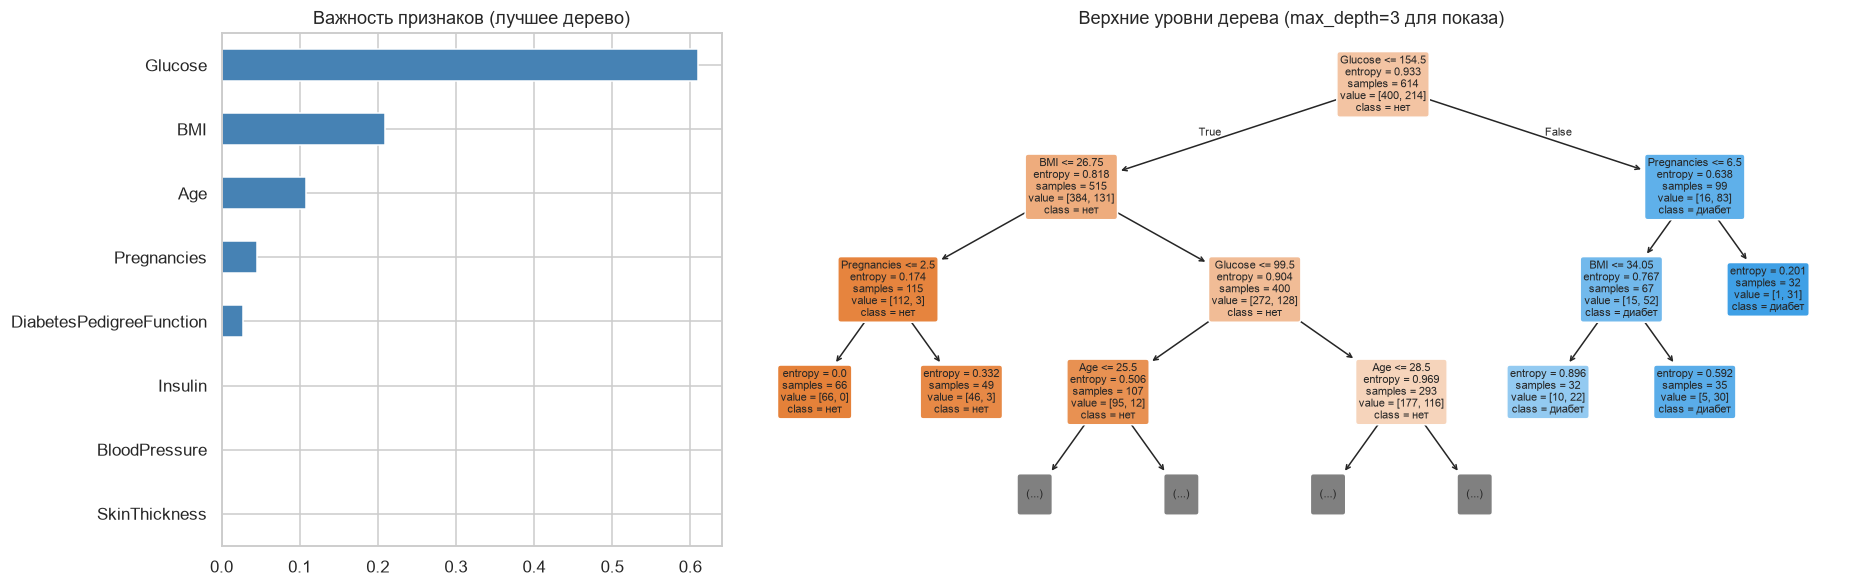

In [47]:
best_tree = gs_dt.best_estimator_.named_steps["clf"]

imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 2.2]})
imp.plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Важность признаков (лучшее дерево)")
plot_tree(best_tree, feature_names=list(X.columns), class_names=["нет", "диабет"],
          filled=True, rounded=True, max_depth=3, fontsize=7, ax=axes[1])
axes[1].set_title("Верхние уровни дерева (max_depth=3 для показа)")
plt.tight_layout()
plt.show()

Показаны важность признаков и верхние уровни лучшего дерева.

Главный признак — **`Glucose`** (корень дерева и более 60% важности), далее `BMI` и `Age`; `Insulin`, `BloodPressure` и `SkinThickness` дерево практически не использует. Это согласуется с корреляциями из раздела 2. Правила легко читаются: например, при `Glucose` ≤ 154,5 и `BMI` ≤ 26,75 диабет почти не встречается.

### 5.3. Линейный дискриминантный анализ

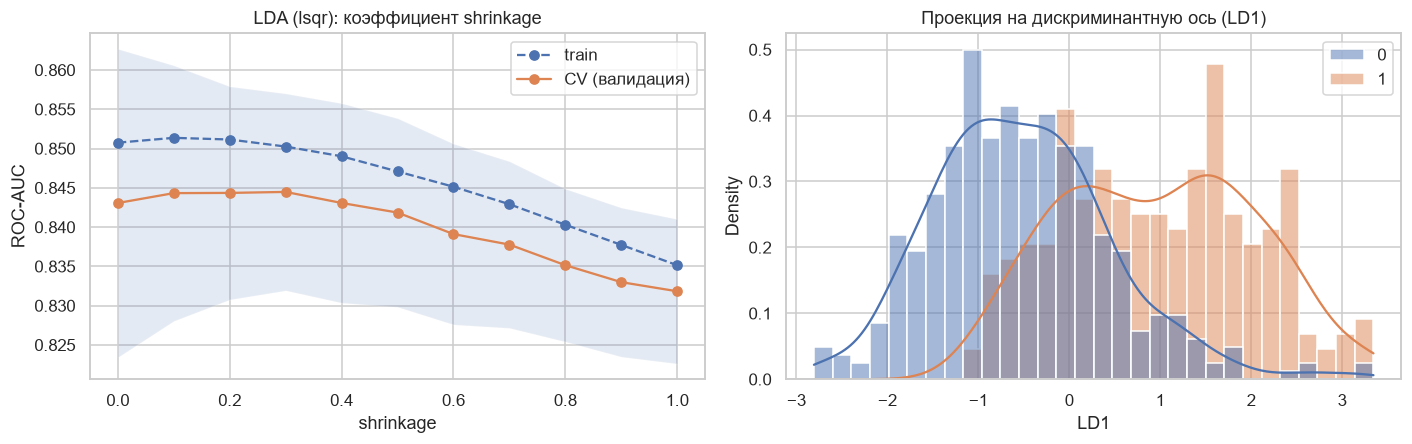

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

plot_curve(axes[0], make_pipe(LinearDiscriminantAnalysis(solver="lsqr")), "clf__shrinkage",
           np.linspace(0, 1, 11), "LDA (lsqr): коэффициент shrinkage", "shrinkage")

lda_vis = LinearDiscriminantAnalysis(solver="svd").fit(X_train_prep, y_train)
z = lda_vis.transform(X_train_prep).ravel()
sns.histplot(x=z, hue=y_train.values, bins=30, kde=True, stat="density", common_norm=False, ax=axes[1])
axes[1].set(title="Проекция на дискриминантную ось (LD1)", xlabel="LD1")
plt.tight_layout()
plt.show()

Слева — влияние коэффициента `shrinkage` (регуляризация ковариационной матрицы), справа — проекция обучающих данных на единственную дискриминантную ось LD1 (для двух классов она одна).

Лучшее качество достигается при небольшом сжатии (0,1–0,3), с ростом `shrinkage` оно слегка падает. Разница небольшая: LDA почти не чувствителен к гиперпараметрам. На проекции видно, что классы сильно перекрываются, но сдвинуты друг относительно друга, что и объясняет умеренное качество всех линейных методов.

In [49]:
lda_grid = [
    {"clf__solver": ["svd"]},
    {"clf__solver": ["lsqr", "eigen"],
     "clf__shrinkage": [None, "auto", 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]},
]
gs_lda = tune("LDA", make_pipe(LinearDiscriminantAnalysis(), "standard"), lda_grid)

cv_lda = pd.DataFrame(gs_lda.cv_results_)
display(cv_lda.groupby("param_clf__solver")["mean_test_score"].agg(["mean", "max"]).round(4))

LDA: CV ROC-AUC = 0.8445, лучшие параметры: {'shrinkage': 0.3, 'solver': 'lsqr'}


,mean,max
param_clf__solver,,
eigen,0.8409,0.8445
lsqr,0.8409,0.8445
svd,0.8431,0.8431


Перебрал `solver` и `shrinkage`.

Лучший вариант: `solver='lsqr'`, `shrinkage=0.3`, CV ROC-AUC **0,8445** (был 0,843). Все три решателя дают практически одно и то же качество (0,841–0,843 в среднем), настройка почти ничего не меняет.

### 5.4. Метод опорных векторов

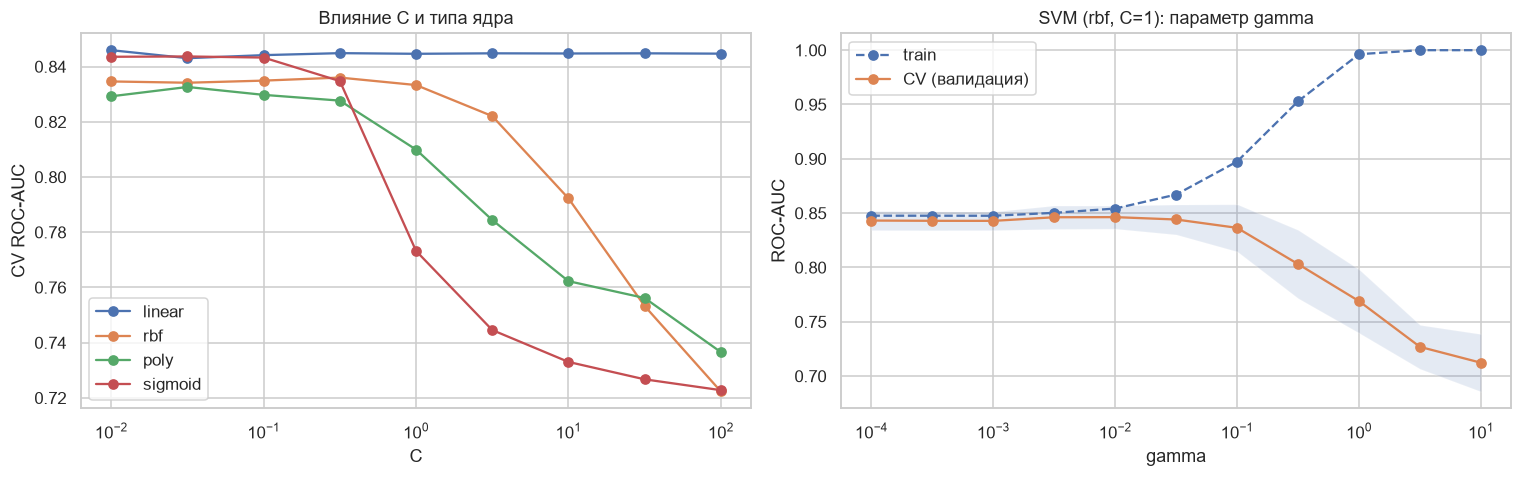

In [50]:
svm_pipe = lambda **kw: make_pipe(SVC(random_state=SEED, **kw), "standard")
C_range = np.logspace(-2, 2, 9)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for kernel in ["linear", "rbf", "poly", "sigmoid"]:
    _, va = validation_curve(svm_pipe(kernel=kernel), X_train, y_train, param_name="clf__C",
                             param_range=C_range, cv=cv, scoring="roc_auc", n_jobs=-1)
    axes[0].plot(C_range, va.mean(1), "o-", label=kernel)
axes[0].set(xscale="log", xlabel="C", ylabel="CV ROC-AUC", title="Влияние C и типа ядра")
axes[0].legend()

plot_curve(axes[1], svm_pipe(kernel="rbf", C=1), "clf__gamma", np.logspace(-4, 1, 11),
           "SVM (rbf, C=1): параметр gamma", "gamma", log=True)
plt.tight_layout()
plt.show()

Слева сравнил четыре ядра при разных `C`, справа показал влияние `gamma` для ядра rbf.

- **Линейное ядро** почти не зависит от `C` и стабильно держится около 0,845.
- У **rbf, poly и sigmoid** при росте `C` качество на CV падает — сказывается переобучение.
- **`gamma` (rbf):** при малых значениях (до ~$10^{-2}$) CV-качество стабильно и высокое. При $\gamma \gtrsim 1$ качество на train близко к 1, а на CV падает до 0,71 — модель запоминает обучающие точки.

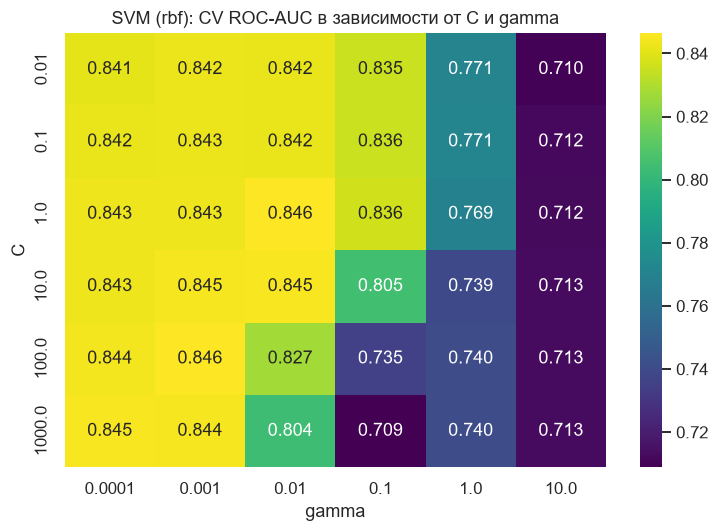

In [51]:
heat_grid = {"clf__C": np.logspace(-2, 3, 6), "clf__gamma": np.logspace(-4, 1, 6)}
gs_heat = GridSearchCV(svm_pipe(kernel="rbf"), heat_grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)

res = pd.DataFrame(gs_heat.cv_results_)
heat = res.assign(C=res["param_clf__C"].astype(float), gamma=res["param_clf__gamma"].astype(float)) \
          .pivot(index="C", columns="gamma", values="mean_test_score")

plt.figure(figsize=(7, 5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis")
plt.title("SVM (rbf): CV ROC-AUC в зависимости от C и gamma")
plt.tight_layout()
plt.show()

Посчитал ROC-AUC на кросс-валидации для сетки значений `C` и `gamma` (ядро rbf) и построил тепловую карту.

Хорошая область — **малые `gamma` (≤ 0,01)** при любых `C`; там AUC ≈ 0,84–0,85. При больших `gamma` ядро слишком «узкое», и качество резко падает. Видно также, что большие `C` допустимы только вместе с малыми `gamma`: при `C ≥ 10` и `gamma ≥ 0,1` — переобучение. Оптимум при малой `gamma` фактически близок к линейной границе.

In [52]:
svm_grid = [
    {"clf__kernel": ["linear"],  "clf__C": [0.01, 0.1, 1, 10, 100]},
    {"clf__kernel": ["rbf"],     "clf__C": [0.1, 1, 10, 100, 1000], "clf__gamma": ["scale", 0.001, 0.01, 0.1, 1]},
    {"clf__kernel": ["poly"],    "clf__C": [0.1, 1, 10], "clf__degree": [2, 3, 4], "clf__gamma": ["scale"]},
    {"clf__kernel": ["sigmoid"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
]
gs_svm = tune("SVM", svm_pipe(), svm_grid)

cv_svm = pd.DataFrame(gs_svm.cv_results_)
display(cv_svm.groupby("param_clf__kernel")["mean_test_score"].agg(["mean", "max"]).round(4))

SVM: CV ROC-AUC = 0.8464, лучшие параметры: {'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}


,mean,max
param_clf__kernel,,
linear,0.8448,0.8459
poly,0.6970,0.8298
rbf,0.7982,0.8464
sigmoid,0.8104,0.8458


Перебрал ядра и их параметры одной сеткой.

Лучшая конфигурация: **rbf, `C=100`, `gamma=0.001`**, CV ROC-AUC **0,846** (было 0,833). По ядрам лучшие значения почти равны у linear (0,846), rbf (0,846) и sigmoid (0,846), а средние результаты различаются заметно: у linear 0,845, у sigmoid 0,810, у rbf 0,798 и у poly всего 0,697. Линейное ядро надёжнее остальных, а нелинейным ядрам нужно аккуратно подбирать `gamma` и `C`. Вывод: граница между классами на этих данных близка к линейной.

### 5.5. Метод ближайших соседей

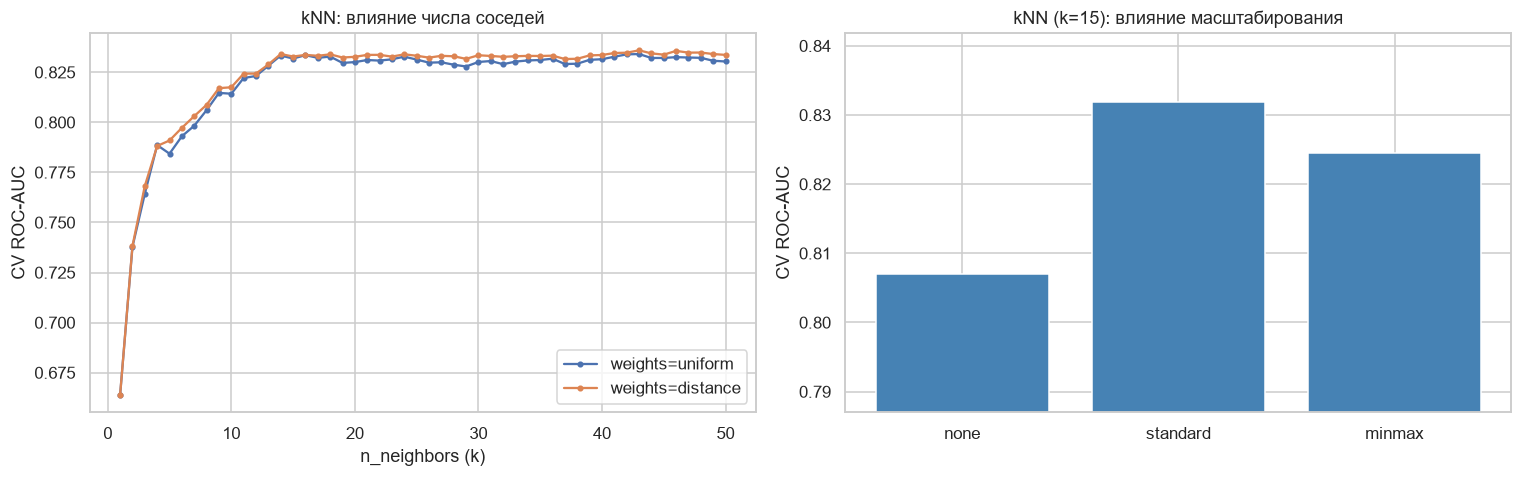

{'none': 0.807, 'standard': 0.8318, 'minmax': 0.8245}


In [53]:
ks = np.arange(1, 51)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for w in ["uniform", "distance"]:
    _, va = validation_curve(make_pipe(KNeighborsClassifier(weights=w)), X_train, y_train,
                             param_name="clf__n_neighbors", param_range=ks, cv=cv, scoring="roc_auc", n_jobs=-1)
    axes[0].plot(ks, va.mean(1), "o-", ms=3, label=f"weights={w}")
axes[0].set(xlabel="n_neighbors (k)", ylabel="CV ROC-AUC", title="kNN: влияние числа соседей")
axes[0].legend()

scaler_scores = {}
for sc in ["none", "standard", "minmax"]:
    scaler_scores[sc] = cross_val_score(make_pipe(KNeighborsClassifier(n_neighbors=15), sc),
                                        X_train, y_train, cv=cv, scoring="roc_auc").mean()
axes[1].bar(list(scaler_scores), list(scaler_scores.values()), color="steelblue")
axes[1].set_ylim(min(scaler_scores.values()) - 0.02, max(scaler_scores.values()) + 0.01)
axes[1].set(title="kNN (k=15): влияние масштабирования", ylabel="CV ROC-AUC")
plt.tight_layout()
plt.show()
print({k: round(float(v), 4) for k, v in scaler_scores.items()})

Слева — зависимость качества от числа соседей `k` для двух схем весов, справа — влияние масштабирования признаков при `k = 15`.

- При `k = 1` качество низкое (≈0,66): модель реагирует на шум. С ростом `k` оно быстро растёт и выходит на плато при `k ≈ 15–20`, дальше растёт очень медленно. Взвешивание по расстоянию (`distance`) чуть лучше `uniform`.
- **Масштабирование важно:** без него CV AUC 0,807, со стандартизацией 0,832, с MinMax 0,825. Без масштабирования признак `Insulin` с большим диапазоном значений доминирует в расстоянии.

In [54]:
knn_grid = {
    "clf__n_neighbors": np.arange(1, 62, 2),
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan", "chebyshev"],
}
gs_knn = tune("kNN", make_pipe(KNeighborsClassifier(), "standard"), knn_grid)

cv_knn = pd.DataFrame(gs_knn.cv_results_)
display(cv_knn.groupby("param_clf__metric")["mean_test_score"].agg(["mean", "max"]).round(4))

kNN: CV ROC-AUC = 0.8365, лучшие параметры: {'metric': 'manhattan', 'n_neighbors': 45, 'weights': 'distance'}


,mean,max
param_clf__metric,,
chebyshev,0.8114,0.8303
euclidean,0.8213,0.8359
manhattan,0.8183,0.8365


Перебрал `n_neighbors` (нечётные от 1 до 61), `weights` и `metric`.

Лучшая конфигурация: `n_neighbors=45`, `weights='distance'`, `metric='manhattan'`, CV ROC-AUC **0,8365** (было 0,784, прирост +0,05). Евклидова метрика по среднему качеству лучше манхэттенской и Чебышёва, но на лучшем сочетании манхэттенская чуть впереди, разница мала.

### 5.6. Итог настройки

In [55]:
pd.set_option("display.max_colwidth", None)
rows = []
for name, gs in searches.items():
    before = baseline_df.loc[name, "CV ROC-AUC (train)"]
    rows.append({"Модель": name, "CV AUC до": before, "CV AUC после": gs.best_score_,
                 "Прирост": gs.best_score_ - before, "Лучшие параметры": clean_params(gs.best_params_)})
tuning_summary = pd.DataFrame(rows).set_index("Модель")
display(tuning_summary.round(4))

,CV AUC до,CV AUC после,Прирост,Лучшие параметры
Модель,,,,
GaussianNB,0.8281,0.8302,0.0020,{'var_smoothing': 1.0}
MultinomialNB,0.7222,0.7224,0.0001,"{'alpha': 3.162278, 'fit_prior': True}"
ComplementNB,0.7222,0.7224,0.0001,"{'alpha': 3.162278, 'fit_prior': True, 'norm': False}"
BernoulliNB,0.5287,0.7735,0.2448,"{'alpha': 100.0, 'binarize': 0.4, 'fit_prior': True}"
DecisionTree,0.6510,0.8055,0.1545,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 30, 'min_samples_split': 2}"
LDA,0.8431,0.8445,0.0014,"{'shrinkage': 0.3, 'solver': 'lsqr'}"
SVM,0.8333,0.8464,0.0131,"{'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}"
kNN,0.7843,0.8365,0.0522,"{'metric': 'manhattan', 'n_neighbors': 45, 'weights': 'distance'}"


Собрал в одну таблицу качество на кросс-валидации до и после настройки.

- Сильнее всего настройка помогла моделям, у которых параметры по умолчанию были неудачными: **BernoulliNB** (+0,245), **дерево решений** (+0,155) и **kNN** (+0,052).
- Моделям с хорошими значениями по умолчанию (**LDA, GaussianNB, SVM**) настройка дала лишь +0,001…+0,013. Они уже были близки к пределу, который задают сами данные.
- После настройки лучшие по CV — **SVM (0,846)**, **LDA (0,845)** и **kNN (0,837)**; они мало различаются между собой.

## 6. Нейронная сеть на TensorFlow

**Задача:** бинарная классификация, на выходе вероятность диабета. Использую полносвязную сеть (MLP) в Keras.

**Базовая архитектура:** вход (8 признаков) → `Dense(16, relu)` → `Dense(8, relu)` → `Dense(1, sigmoid)`.
- **Скрытые слои и ReLU** — нелинейность, позволяющая строить сложную границу.
- **Сигмоида на выходе** — выдаёт вероятность класса 1 в диапазоне [0, 1].
- **Функция потерь:** бинарная кросс-энтропия (`binary_crossentropy`).
- **Оптимизатор:** Adam, `learning_rate = 1e-3`.
- **Метрики при обучении:** accuracy и AUC.

Для контроля переобучения выделяю из обучающей выборки валидационную часть (20%). Тестовая выборка остаётся нетронутой. Каждый запуск пишет логи в TensorBoard.

In [56]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)

LOG_ROOT = "logs/fit"
shutil.rmtree("logs", ignore_errors=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


Подключил TensorFlow, зафиксировал seed и задал папку `logs/fit` для TensorBoard. Старые логи удаляются, чтобы запуски не смешивались.

In [57]:
# Отдельная валидационная выборка (из train), чтобы следить за переобучением.
# Тест по-прежнему не трогаем до самого конца.
X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

# импутация медианой + стандартизация, параметры считаем только по обучающей части
prep_nn = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())]).fit(X_tr_raw)

Xtr, Xva, Xte = (prep_nn.transform(d).astype("float32") for d in (X_tr_raw, X_val_raw, X_test))
ytr, yva, yte = (v.values.astype("float32") for v in (y_tr, y_val, y_test))

print("train / val / test:", Xtr.shape, Xva.shape, Xte.shape)

train / val / test: (491, 8) (123, 8) (154, 8)


Разбил обучающую выборку на обучающую часть (491 объект) и валидационную (123 объекта), заполнил пропуски и стандартизировали признаки. Параметры предобработки считаются только по обучающей части.

In [58]:
def build_model(hidden=(16, 8), activation="relu", lr=1e-3, dropout=0.0):
    """Полносвязная сеть: входной слой -> скрытые Dense (+Dropout) -> Dense(1, sigmoid)."""
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(Xtr.shape[1],)))
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

build_model().summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Написал функцию `build_model`, которая собирает сеть с заданными числом нейронов в слоях, функцией активации, скоростью обучения и dropout, и вывел структуру базовой модели. Базовая сеть содержит 8·16+16 + 16·8+8 + 8·1+1 = **289 обучаемых параметров**.

In [59]:
def run_experiment(name, hidden=(16, 8), activation="relu", lr=1e-3, dropout=0.0,
                   batch_size=32, epochs=100, patience=None, histogram_freq=0):
    """Обучает сеть с заданными гиперпараметрами и пишет логи в TensorBoard (logs/fit/<name>)."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(hidden, activation, lr, dropout)

    callbacks = [keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_ROOT, name),
                                             histogram_freq=histogram_freq)]
    if patience:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                       restore_best_weights=True))
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs,
                     batch_size=batch_size, callbacks=callbacks, verbose=0)
    return model, pd.DataFrame(hist.history)

def plot_history(h, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation")
    axes[0].set(title=f"{title}: loss", xlabel="эпоха", ylabel="binary crossentropy")
    axes[1].plot(h["accuracy"], label="train"); axes[1].plot(h["val_accuracy"], label="validation")
    axes[1].set(title=f"{title}: accuracy", xlabel="эпоха", ylabel="accuracy")
    axes[0].legend(); axes[1].legend()
    plt.tight_layout(); plt.show()

Написал функцию `run_experiment`: она обучает сеть с заданными гиперпараметрами, перед каждым запуском фиксирует seed (чтобы сравнение было честным) и подключает колбэк `TensorBoard`. При необходимости можно включить `EarlyStopping`, который останавливает обучение, когда `val_loss` перестаёт улучшаться, и возвращает лучшие веса. Функция `plot_history` рисует графики loss и accuracy на обучении и валидации.

### 6.1. Базовая сеть и число эпох

Обучаю базовую сеть заметно дольше, чем нужно (200 эпох), чтобы увидеть, как число эпох влияет на качество.

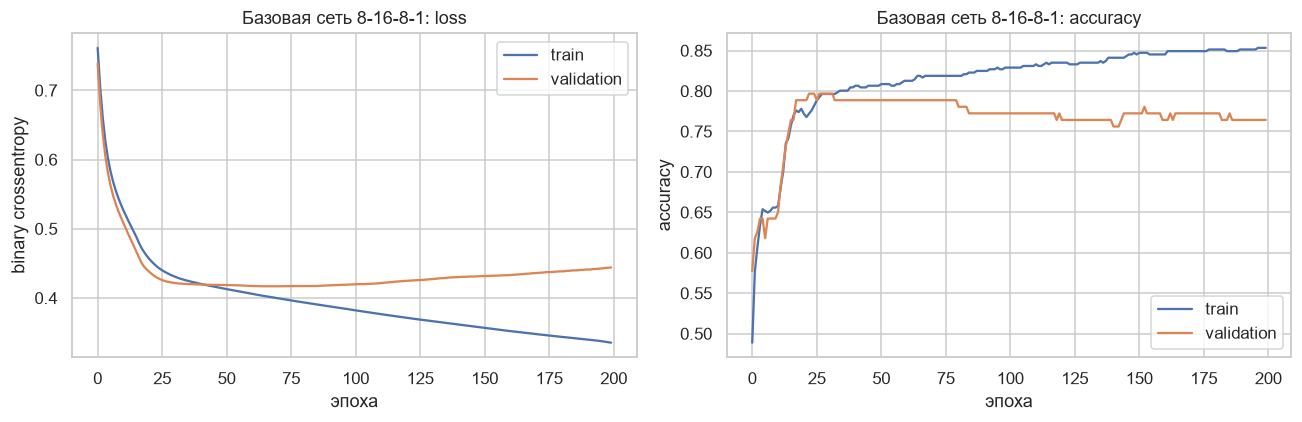

Минимум val_loss = 0.4168 на эпохе 70 из 200
В конце обучения: train loss = 0.3354, val loss = 0.4441


In [60]:
model_base, h_base = run_experiment("00_baseline", epochs=200)
plot_history(h_base, "Базовая сеть 8-16-8-1")

b = h_base["val_loss"].idxmin()
print(f"Минимум val_loss = {h_base.loc[b, 'val_loss']:.4f} на эпохе {b + 1} из {len(h_base)}")
print(f"В конце обучения: train loss = {h_base['loss'].iloc[-1]:.4f}, val loss = {h_base['val_loss'].iloc[-1]:.4f}")

Обучил базовую сеть 200 эпох и построил кривые обучения.

Пока loss на обучении и на валидации падают вместе, сеть учится. Когда loss на обучении продолжает падать, а `val_loss` начинает расти, наступает **переобучение**. Эпоха с минимальным `val_loss` (она выведена под графиком) — оптимальное число эпох для этой конфигурации. Дальнейшее обучение только ухудшает обобщающую способность. Поэтому в итоговой модели используется ранняя остановка.

### 6.2. Исследование гиперпараметров

Меняю **по одному** гиперпараметру, остальные оставляю базовыми (сеть 16-8, ReLU, batch 32, lr = 1e-3, 100 эпох). Для каждого запуска считаю минимальный `val_loss` (`best_val_loss`), эпоху этого минимума, accuracy и AUC на валидации в этой эпохе, а также loss в конце обучения. Разрыв между `final_train_loss` и `final_val_loss` показывает степень переобучения.

In [61]:
def fmt(v):
    return "-".join(map(str, v)) if isinstance(v, (tuple, list)) else str(v)

def study(group, param, values, epochs=100, **base_cfg):
    """Меняем один гиперпараметр, остальные фиксированы. Возвращает таблицу и истории обучения."""
    histories, rows = {}, []
    for v in values:
        _, h = run_experiment(f"{group}/{fmt(v)}", epochs=epochs, **{**base_cfg, param: v})
        histories[fmt(v)] = h
        b = h["val_loss"].idxmin()
        rows.append({param: fmt(v),
                     "best_val_loss": h.loc[b, "val_loss"], "best_epoch": b + 1,
                     "val_acc@best": h.loc[b, "val_accuracy"], "val_auc@best": h.loc[b, "val_auc"],
                     "final_val_loss": h["val_loss"].iloc[-1], "final_train_loss": h["loss"].iloc[-1]})
    return pd.DataFrame(rows).set_index(param), histories

def plot_study(histories, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for k, h in histories.items():
        axes[0].plot(h["val_loss"], label=k)
        axes[1].plot(h["val_accuracy"], label=k)
    axes[0].set(title=f"{title}: val_loss", xlabel="эпоха")
    axes[1].set(title=f"{title}: val_accuracy", xlabel="эпоха")
    axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

def best_value(table, values):
    """Значение гиперпараметра с минимальным best_val_loss."""
    label = table["best_val_loss"].idxmin()
    return next(v for v in values if fmt(v) == label)

Написал функцию `study`: она перебирает значения одного гиперпараметра, запускает обучение, собирает результаты в таблицу и сохраняет истории обучения. Функция `best_value` возвращает значение с минимальным `val_loss`. Сравнение идёт по валидационной выборке, **тест не используется**.

,best_val_loss,best_epoch,val_acc@best,val_auc@best,final_val_loss,final_train_loss
batch_size,,,,,,
8,0.4231,46,0.7805,0.8683,0.4584,0.3402
16,0.4168,51,0.7886,0.8772,0.4280,0.3617
32,0.4168,70,0.7886,0.8741,0.4196,0.3826
64,0.4162,95,0.7886,0.8719,0.4162,0.4010
128,0.4176,100,0.7886,0.8711,0.4176,0.4199


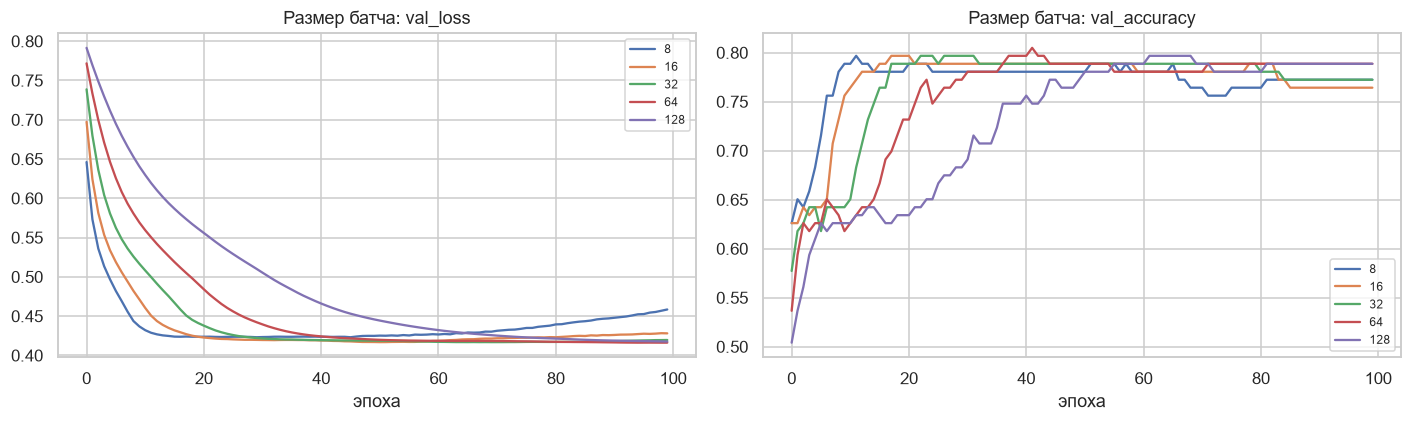

In [62]:
batch_values = [8, 16, 32, 64, 128]
t_batch, h_batch = study("01_batch_size", "batch_size", batch_values)
display(t_batch.round(4))
plot_study(h_batch, "Размер батча")

Сравнил размеры батча 8, 16, 32, 64 и 128.

Лучший `val_loss` у всех вариантов почти одинаковый (0,416–0,423), то есть размер батча на качество практически не влияет. Зато он сильно влияет на скорость обучения: `best_epoch` растёт с размером батча (46, 51, 70, 95 и 100 эпох). Малые батчи делают больше обновлений за эпоху, быстрее доходят до минимума и затем переобучаются: у batch = 8 `final_val_loss` 0,458 при минимуме 0,423. У batch = 64 и 128 кривая плавная, `final_val_loss` практически равен минимуму (0,416 и 0,418), а минимум достигается к концу 100 эпох.

,best_val_loss,best_epoch,val_acc@best,val_auc@best,final_val_loss,final_train_loss
hidden,,,,,,
8,0.4087,91,0.7724,0.8839,0.4090,0.4319
32,0.4185,34,0.7886,0.8706,0.4194,0.3991
16-8,0.4168,70,0.7886,0.8741,0.4196,0.3826
32-16,0.4105,17,0.8130,0.8826,0.4738,0.3162
64-32-16,0.4135,6,0.7805,0.8791,0.7297,0.0854
64-64-64,0.4163,5,0.7967,0.8709,1.5613,0.0058


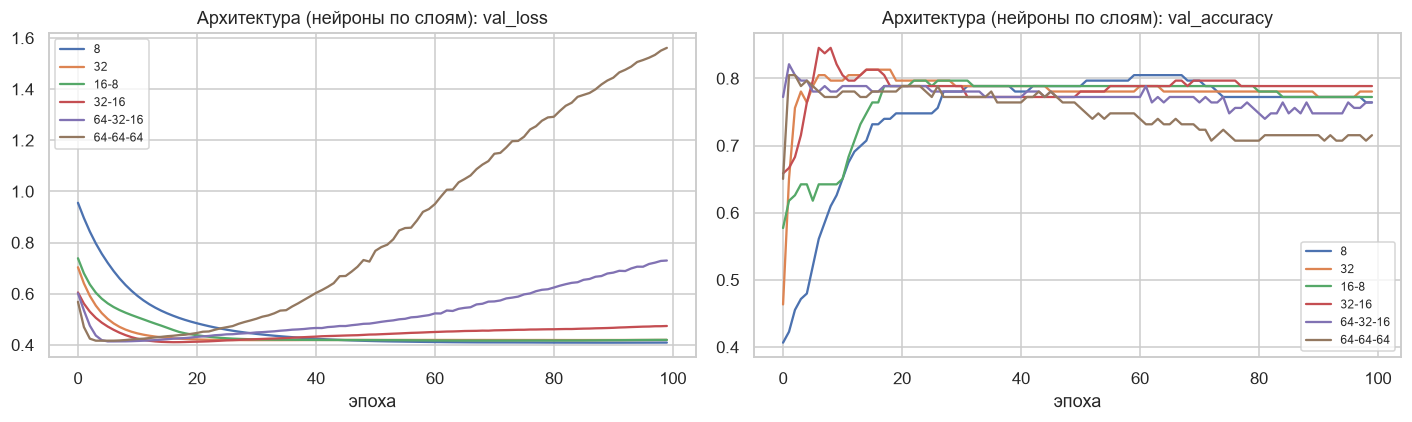

In [63]:
arch_values = [(8,), (32,), (16, 8), (32, 16), (64, 32, 16), (64, 64, 64)]
t_arch, h_arch = study("02_architecture", "hidden", arch_values)
display(t_arch.round(4))
plot_study(h_arch, "Архитектура (нейроны по слоям)")

Сравнил шесть архитектур: от одного слоя на 8 нейронов до трёх слоёв по 64 нейрона.

Минимальный `val_loss` у всех архитектур близок (0,409–0,419), а лучший результат у самой простой сети с 8 нейронами (0,4087). Различие проявляется в переобучении. Сети 64-32-16 и 64-64-64 достигают минимума уже на 6-й и 5-й эпохах, после чего `val_loss` растёт до 0,73 и 1,56, а train loss падает до 0,085 и 0,006: сеть запоминает обучающую выборку. Простые сети (8 и 16-8) к концу обучения почти не переобучаются (`final_val_loss` 0,409 и 0,420). Для 491 обучающего объекта и 8 признаков большая ёмкость не нужна.

,best_val_loss,best_epoch,val_acc@best,val_auc@best,final_val_loss,final_train_loss
activation,,,,,,
relu,0.4168,70,0.7886,0.8741,0.4196,0.3826
tanh,0.4320,24,0.8130,0.8733,0.4484,0.4149
sigmoid,0.4290,100,0.7967,0.8751,0.4290,0.4583
elu,0.4144,24,0.7967,0.8781,0.4318,0.4162


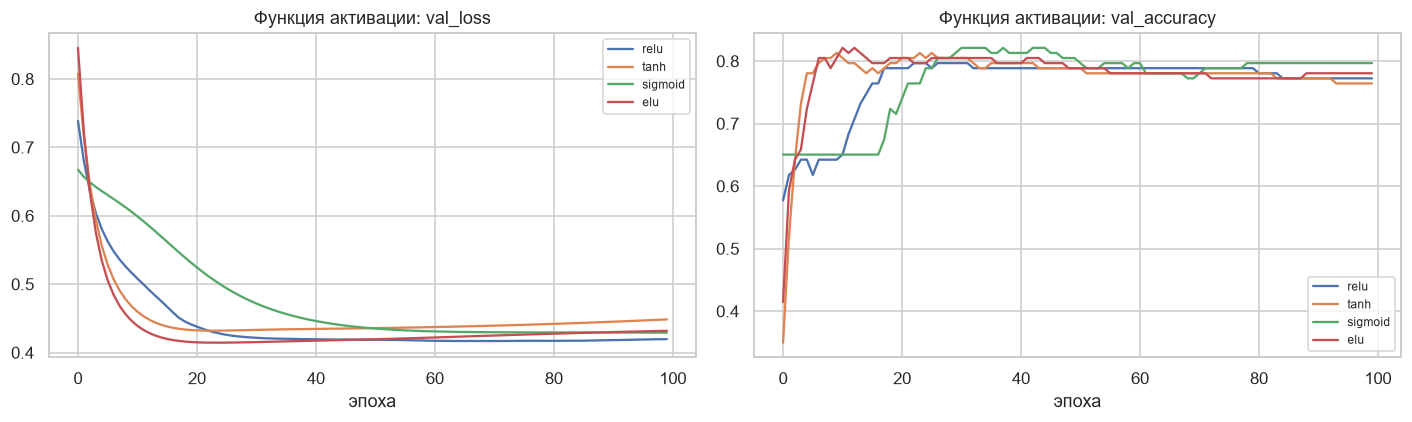

In [64]:
act_values = ["relu", "tanh", "sigmoid", "elu"]
t_act, h_act = study("03_activation", "activation", act_values)
display(t_act.round(4))
plot_study(h_act, "Функция активации")

Сравнил функции активации `relu`, `tanh`, `sigmoid` и `elu` в скрытых слоях.

Различия небольшие: лучший `val_loss` у `elu` (0,4144) и `relu` (0,4168), у `sigmoid` 0,4290, у `tanh` 0,4320. `Sigmoid` обучается медленнее остальных: минимум достигнут на последней, 100-й эпохе, то есть сеть ещё не дошла до предела. У `relu` минимум на 70-й эпохе, у `elu` и `tanh` на 24-й. Для такой небольшой сети выбор активации не критичен.

,best_val_loss,best_epoch,val_acc@best,val_auc@best,final_val_loss,final_train_loss
lr,,,,,,
0.0001,0.5153,100,0.6504,0.7866,0.5153,0.5290
0.001,0.4168,70,0.7886,0.8741,0.4196,0.3826
0.01,0.4192,4,0.7805,0.8765,1.3759,0.0910
0.1,0.4404,3,0.7886,0.8487,1.2106,0.3817


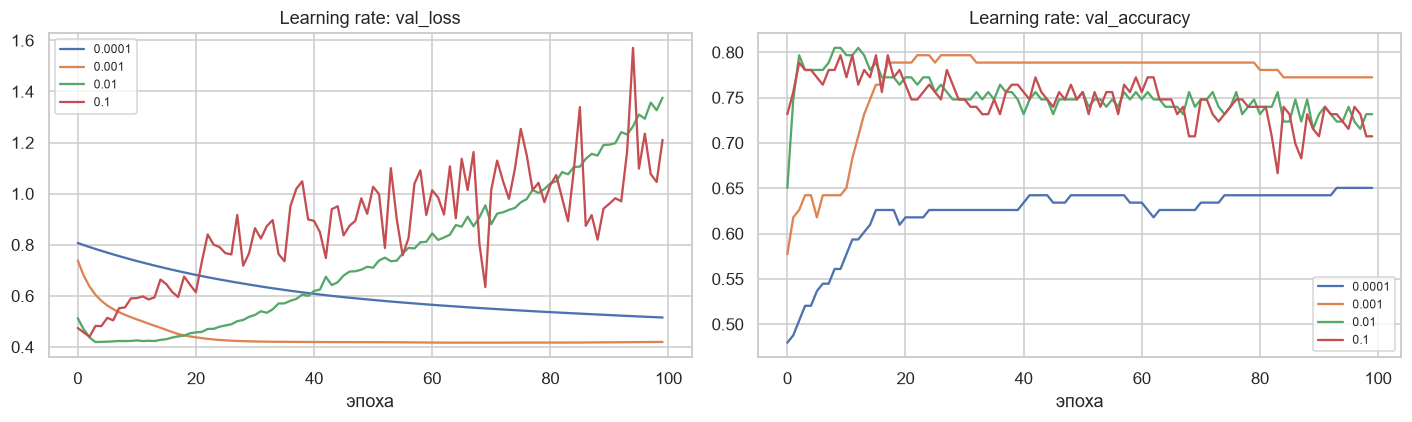

In [65]:
lr_values = [1e-4, 1e-3, 1e-2, 1e-1]
t_lr, h_lr = study("04_learning_rate", "lr", lr_values)
display(t_lr.round(4))
plot_study(h_lr, "Learning rate")

Сравнил скорость обучения Adam: 1e-4, 1e-3, 1e-2 и 1e-1.

- **1e-4** слишком мала: за 100 эпох сеть не дошла до минимума (`val_loss` 0,515, accuracy 0,65, минимум на последней эпохе).
- **1e-3** показала лучший результат (`val_loss` 0,4168), обучение стабильное.
- **1e-2** достигает почти того же минимума (0,4192), но уже на 4-й эпохе и затем сильно переобучается: `final_val_loss` 1,376, train loss 0,091.
- **1e-1** слишком велика: минимум хуже всех (0,4404) на 3-й эпохе, `val_loss` затем растёт до 1,21.

Оптимальной оказалась скорость 1e-3; при 1e-2 без ранней остановки модель быстро переобучается.

,best_val_loss,best_epoch,val_acc@best,val_auc@best,final_val_loss,final_train_loss
dropout,,,,,,
0.0,0.4135,6,0.7805,0.8791,0.7297,0.0854
0.2,0.4159,14,0.7967,0.8737,0.5019,0.3452
0.4,0.4075,33,0.7886,0.8775,0.4193,0.4350


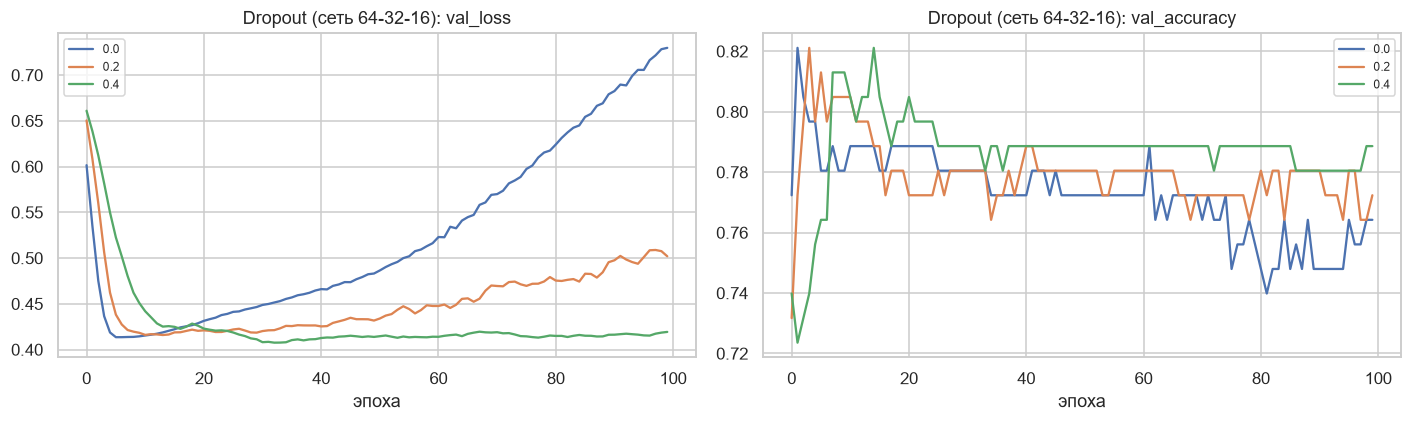

In [66]:
do_values = [0.0, 0.2, 0.4]
t_do, h_do = study("05_dropout", "dropout", do_values, hidden=(64, 32, 16))
display(t_do.round(4))
plot_study(h_do, "Dropout (сеть 64-32-16)")

Взял сеть 64-32-16 (достаточно ёмкую, чтобы переобучаться) и сравнил dropout 0, 0.2 и 0.4.

Dropout случайно «выключает» часть нейронов при обучении, это регуляризует сеть. Эффект хорошо виден: без dropout `final_val_loss` 0,730 при train loss 0,085 (сильное переобучение), при 0,2 — 0,502, при 0,4 — 0,419 при train loss 0,435. Dropout 0,4 дал и лучший минимум `val_loss` (0,4075), причём достигается он только на 33-й эпохе, то есть сеть учится дольше и устойчивее. На этой выборке сильная регуляризация полезна.

### 6.3. Итоговая сеть

Объединил лучшие значения каждого исследованного гиперпараметра (по минимальному `val_loss`), обучил до 300 эпох с ранней остановкой (`patience=30`, возвращаются веса лучшей эпохи) и включил запись гистограмм весов для TensorBoard.

Итоговая конфигурация: {'hidden': (8,), 'activation': 'elu', 'batch_size': 64, 'lr': 0.001, 'dropout': 0.4}


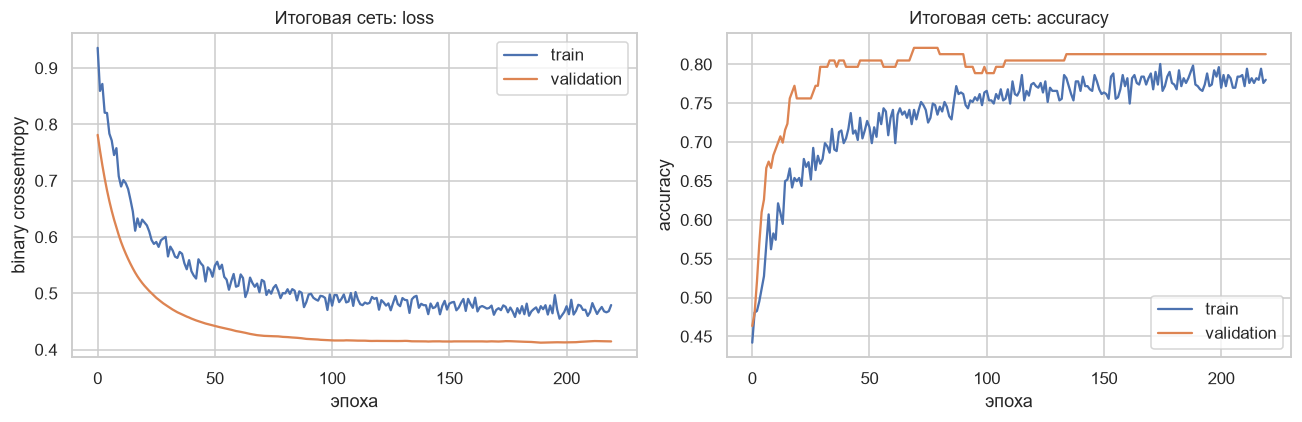

Обучение остановлено на эпохе: 220 | лучший val_loss: 0.4123


In [67]:
best_cfg = {
    "hidden":     best_value(t_arch, arch_values),
    "activation": best_value(t_act, act_values),
    "batch_size": best_value(t_batch, batch_values),
    "lr":         best_value(t_lr, lr_values),
    "dropout":    best_value(t_do, do_values),
}
print("Итоговая конфигурация:", best_cfg)

# ранняя остановка по val_loss + гистограммы весов в TensorBoard
model_nn, h_final = run_experiment("06_final", epochs=300, patience=30, histogram_freq=1, **best_cfg)
plot_history(h_final, "Итоговая сеть")
print("Обучение остановлено на эпохе:", len(h_final), "| лучший val_loss:", round(h_final["val_loss"].min(), 4))

Из таблиц выше автоматически выбраны лучшие значения гиперпараметров: сеть с одним скрытым слоем на **8 нейронов**, активация `elu`, batch 64, learning rate 1e-3, dropout 0,4. Обучение остановилось на эпохе 220 (лучшие веса взяты с эпохи 190), лучший `val_loss` равен 0,4123.

Здесь есть две оговорки. Во-первых, выбор делается по `val_loss` на небольшой валидационной выборке (123 объекта), поэтому он содержит шум: минимальные `val_loss` разных конфигураций различаются в третьем знаке, и при другом seed «лучшая» могла бы поменяться. Во-вторых, лучшие значения подбирались по одному, а сочетание не проверялось. Dropout 0,4 выбран на сети 64-32-16, а в итоговой сети всего 8 нейронов, и такая регуляризация для неё, скорее всего, избыточна. Итоговый `val_loss` (0,4123) ненамного лучше базовой сети (0,4168), так что выигрыш от подбора минимален.

In [68]:
y_score_nn = model_nn.predict(Xte, verbose=0).ravel()
y_pred_nn = (y_score_nn >= 0.5).astype(int)

register("Neural Network (TF)", y_pred_nn, y_score_nn)
pd.Series(results["Neural Network (TF)"]).round(3).to_frame("тест")

,тест
Accuracy,0.701
Precision,0.583
Recall,0.519
F1,0.549
ROC-AUC,0.804


Оценил итоговую сеть на тестовой выборке (порог 0,5) и сохранил результаты для общего сравнения.

### 6.4. Мониторинг обучения в TensorBoard

Все запуски записаны в `logs/fit/<эксперимент>`. Ниже — запуск TensorBoard прямо в блокноте.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir logs/fit


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 1576), started 0:01:38 ago. (Use '!kill 1576' to kill it.)

Запустил TensorBoard на папке `logs/fit` (http://localhost:6006).

- вкладка **Scalars** — графики `epoch_loss`, `epoch_accuracy`, `epoch_auc` для обучения и валидации (серии `train` и `validation`). Слева можно выбрать нужные запуски: `01_batch_size/…`, `02_architecture/…`, `03_activation/…`, `04_learning_rate/…`, `05_dropout/…`, `06_final`. Так наглядно сравниваются разные гиперпараметры;
- **Distributions / Histograms** (есть только у запуска `06_final`) — как менялись веса слоёв по ходу обучения;
- **Graphs** — вычислительный граф модели.

## 7. Сравнительный анализ

Собираю результаты всех методов на **тестовой выборке**. Для классических моделей показана также средняя ROC-AUC по кросс-валидации на train (`CV ROC-AUC`) — она устойчивее, чем оценка по 154 тестовым объектам. Для нейросети CV не считалась, потому что она оценивалась по отдельной валидационной выборке.

In [70]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
results_df = pd.DataFrame(results).T[METRICS]
cv_auc = pd.Series({n: gs.best_score_ for n, gs in searches.items()}, name="CV ROC-AUC (train)")
display(results_df.join(cv_auc).sort_values("ROC-AUC", ascending=False).round(3))

for m in METRICS:
    print(f"{m:10s} лучший: {results_df[m].idxmax():22s} {results_df[m].max():.3f}")

,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC (train)
DecisionTree,0.779,0.778,0.519,0.622,0.838,0.805
kNN,0.753,0.690,0.537,0.604,0.822,0.837
SVM,0.695,0.578,0.481,0.525,0.817,0.846
Neural Network (TF),0.701,0.583,0.519,0.549,0.804,NaN
LDA,0.701,0.580,0.537,0.558,0.804,0.844
GaussianNB,0.721,0.641,0.463,0.538,0.773,0.830
MultinomialNB,0.649,0.000,0.000,0.000,0.768,0.722
ComplementNB,0.734,0.600,0.722,0.655,0.768,0.722
BernoulliNB,0.656,0.526,0.185,0.274,0.740,0.773


Accuracy   лучший: DecisionTree           0.779
Precision  лучший: DecisionTree           0.778
Recall     лучший: ComplementNB           0.722
F1         лучший: ComplementNB           0.655
ROC-AUC    лучший: DecisionTree           0.838


Свел в таблицу Accuracy, Precision, Recall, F1 и ROC-AUC для всех моделей и вывели лучшую модель по каждой метрике.

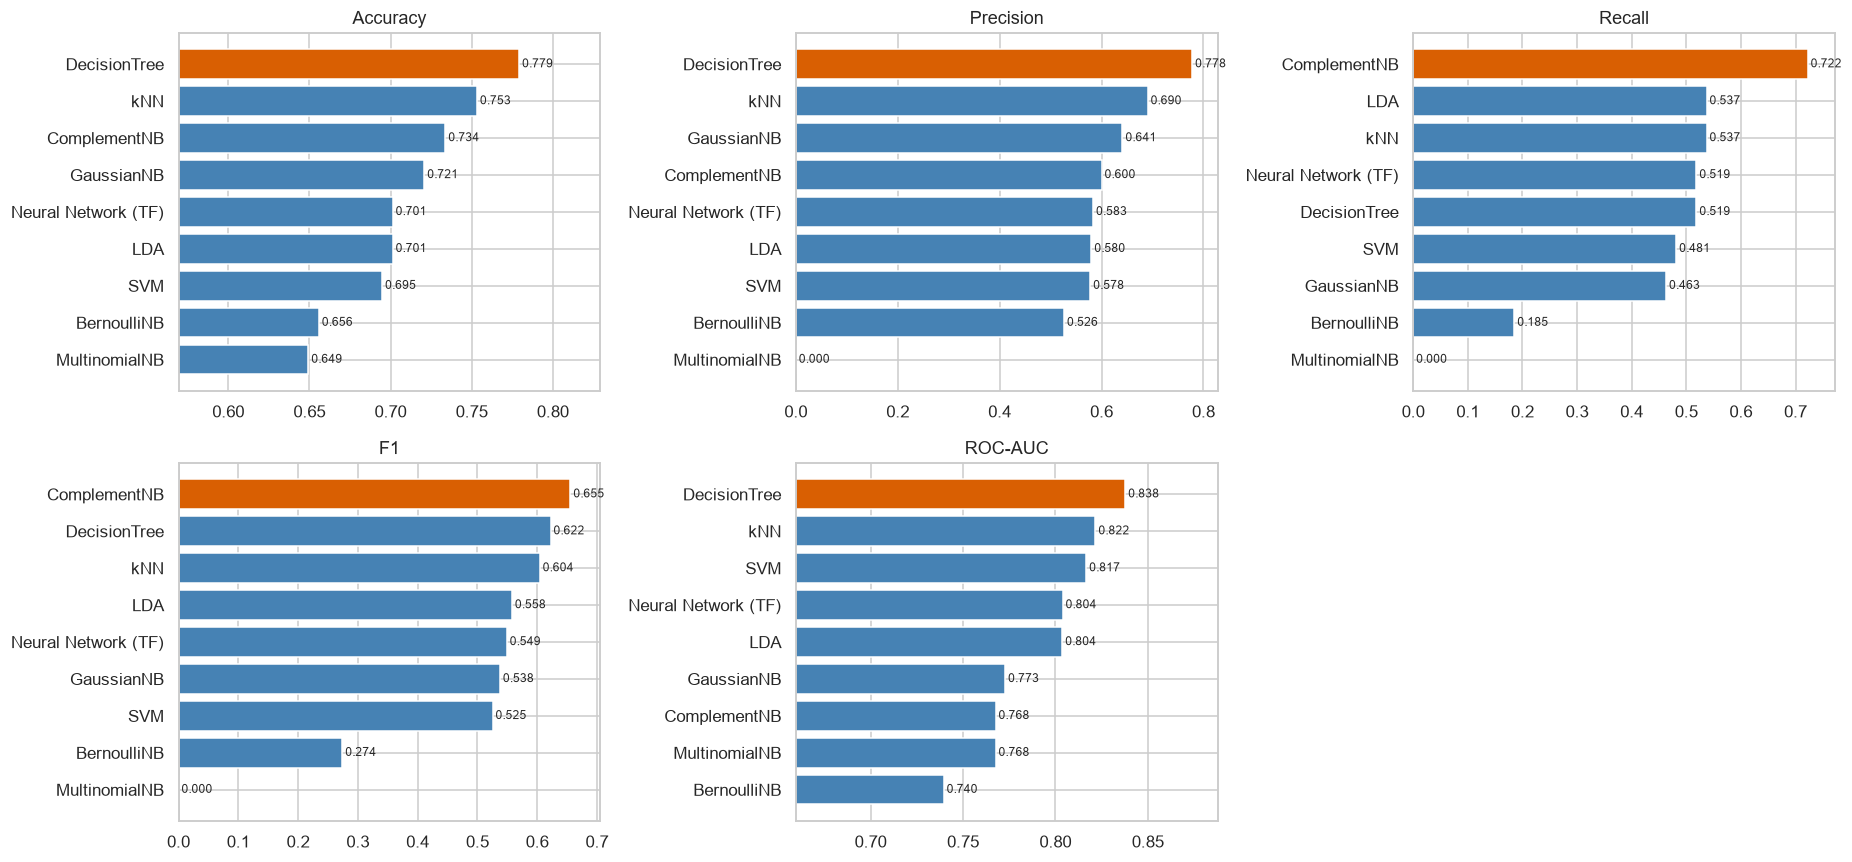

In [71]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, m in zip(axes.ravel(), METRICS):
    s = results_df[m].sort_values()
    colors = ["#d95f02" if i == s.idxmax() else "steelblue" for i in s.index]
    ax.barh(s.index, s.values, color=colors)
    ax.set_xlim(max(0, s.min() - 0.08), min(1, s.max() + 0.05))
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    ax.set_title(m)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

Построил столбчатые диаграммы по каждой метрике; лучшая модель выделена оранжевым.

Ориентиры для чтения: Accuracy следует сравнивать с 0,65 (доля класса 0), а Recall — с точки зрения того, сколько больных модель пропускает. Модели с высокой Precision, но низким Recall, осторожны: ставят диагноз редко, но почти без ошибок. Модели с высоким Recall находят больше больных, но дают больше ложных тревог.

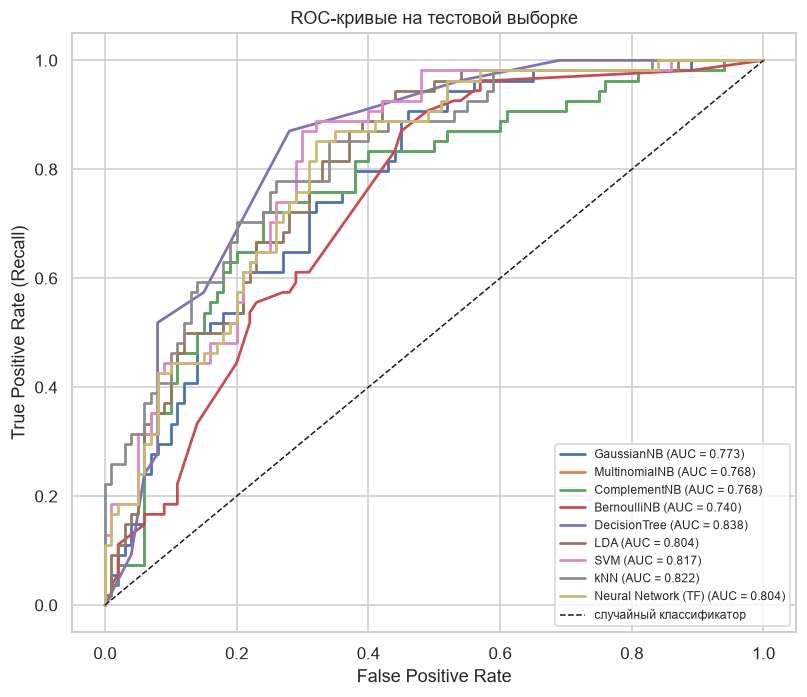

In [72]:
plt.figure(figsize=(7.5, 6.5))
for name, (fpr, tpr) in roc_data.items():
    plt.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривые на тестовой выборке")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Нарисовал ROC-кривые всех моделей на тесте.

Чем ближе кривая к левому верхнему углу, тем лучше модель ранжирует объекты независимо от порога. Модели с близкими кривыми практически равноценны. На маленькой тестовой выборке кривые «шагают» и могут пересекаться, поэтому небольшие различия AUC не показательны.

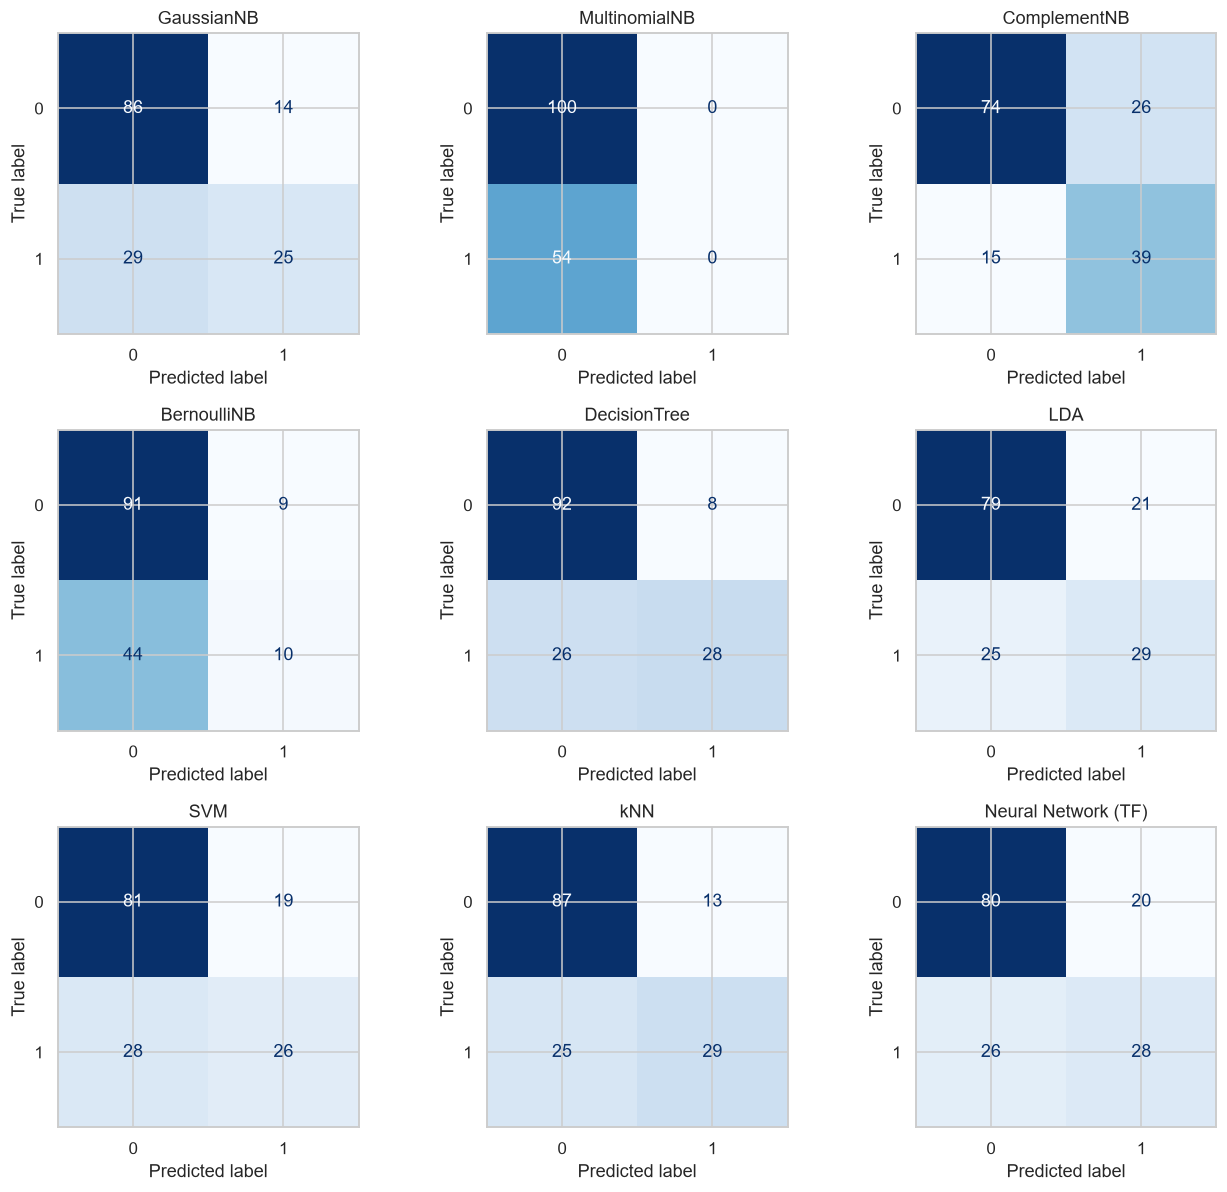

Размер теста: 154. Стандартная ошибка accuracy при p=0.78: ±0.033


In [73]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
for ax in axes.ravel()[len(preds):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

n_test = len(y_test)
p = results_df["Accuracy"].max()
print(f"Размер теста: {n_test}. Стандартная ошибка accuracy при p={p:.2f}: ±{np.sqrt(p * (1 - p) / n_test):.3f}")

Построил матрицы ошибок и оценил статистическую погрешность.

Матрицы показывают, какие ошибки делает каждая модель: сколько больных пропущено (левая нижняя ячейка) и сколько здоровых названо больными (правая верхняя). Стандартная ошибка accuracy при размере теста 154 около ±3,3 п.п., поэтому разницу меньше 3–4 п.п. между моделями считать значимой нельзя.

### Выводы по сравнению

1. **Нет «абсолютного чемпиона».** На маленьком тесте победитель зависит от метрики. Среди классических моделей в моём запуске дерево решений даёт лучшие Accuracy и Precision, ComplementNB — лучший Recall и F1 (но у него низкий AUC), а по ROC-AUC на кросс-валидации лидируют SVM, LDA и kNN. Значит, выбор модели зависит от того, что важнее: точность диагноза или полнота выявления больных.
2. **Самые устойчивые модели — SVM, LDA и kNN.** У них высокий CV ROC-AUC (≈0,84) и небольшой разрыв между CV и тестом. Все три близки к линейной границе, что подтверждают кривые SVM и успех LDA.
3. **Дерево решений** выглядит лучше всего на тесте, но на кросс-валидации его AUC заметно ниже (≈0,81). Часть успеха на тесте — удача малой выборки. Зато дерево лучше всех интерпретируется: главный признак — глюкоза.
4. **Наивный Байес.** GaussianNB подходит для данных, но признаки коррелируют (нарушено допущение независимости). Multinomial, Complement и Bernoulli рассчитаны на счётчики и бинарные признаки и хуже подходят для непрерывных признаков.
5. **Нейронная сеть** (Accuracy 0,701, F1 0,549, ROC-AUC 0,804) на тесте оказалась на уровне LDA и по ROC-AUC уступила дереву решений (0,838), kNN (0,822) и SVM (0,817). Для небольшой табличной выборки из 768 объектов и 8 признаков это ожидаемо: сложная модель не даёт преимущества, а требует больше усилий (валидационная выборка, ранняя остановка, подбор архитектуры и learning rate). Исследование показало, что минимальный `val_loss` у большинства конфигураций почти одинаков (≈0,41–0,43), а различаются они скоростью и степенью переобучения. Заметнее всего на результат влияли learning rate (при 1e-4 сеть не успевает обучиться, при 1e-2 и выше быстро переобучается) и dropout.
6. **Влияние настройки.** Сильнее всего она помогла моделям с неудачными параметрами по умолчанию (дерево, BernoulliNB, kNN). У моделей, которые изначально работали хорошо (LDA, SVM, GaussianNB), прирост небольшой.
7. **Порог 0,5 не оптимален для скрининга.** Recall у большинства моделей около 0,5, то есть каждый второй больной пропускается. Если важно находить больных, порог классификации можно снизить: ROC-кривые показывают, что это возможно ценой роста ложных тревог.

## 8. Заключение

В работе на датасете Pima Indians Diabetes решена задача бинарной классификации (диабет / нет диабета):

- Данные подготовлены: нули в `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` распознаны как скрытые пропуски и заполнены медианой, признаки стандартизованы. Всё это делалось внутри `Pipeline` без утечки информации из теста. Выборка разделена на train/test со стратификацией.
- Построены и сравнены модели наивного Байеса (четыре варианта), дерево решений, LDA, SVM и kNN, а также нейронная сеть на TensorFlow. Качество оценено по Accuracy, Precision, Recall, F1 и ROC-AUC, построены ROC-кривые и диаграммы.
- Для каждого метода исследовано влияние гиперпараметров (кривые валидации, `GridSearchCV`). Показано, что настройка критична для деревьев (контроль глубины), kNN (число соседей, масштабирование), SVM (`gamma` и `C`) и BernoulliNB (порог бинаризации), и мало меняет результат LDA и GaussianNB.
- Для нейросети исследованы число эпох, размер батча, архитектура, функция активации, скорость обучения и dropout; обучение визуализировано в TensorBoard.
- Лучшие и самые устойчивые результаты по кросс-валидации показал SVM, LDA и kNN (CV ROC-AUC ≈ 0,84–0,85). Нейронная сеть на столь малой выборке, как правило, заметного выигрыша не даёт (её результат см. в итоговой таблице). Все модели ограничены самими данными: признаки слабо разделяют классы, а выборка мала, поэтому у лучших моделей качество на тесте составляет порядка 70–78% по accuracy при ROC-AUC около 0,80–0,84.